# StorSeismic — Extended Experiments, Ablations & Report Diagnostics (`nb4`)

This notebook builds directly on the checkpoints saved by **`nb3_mobil_openfwi_section4`** (`./results/mobil_openfwi_section4/`) and implements six comprehensive experiments plus publication-ready diagnostic plots:

### Experiments Implemented
1. **Baseline Diagnostics & SNR Robustness** — Reuses `nb3` checkpoints to verify Mobil field denoising, plot SNR robustness with error bars against a Bandpass baseline, and visualize Good / Average / Failure cases with 1D amplitude spectra.
2. **Experiment A1 — Pre-Training vs. Training from Scratch (Sample Efficiency)** — Compares pre-trained vs. randomly initialized models across `10%, 25%, 50%, 100%` of OpenFWI labels.
3. **Experiment A2 — Partial Layer Freezing Sweep (Section 6.3)** — Sweeps `num_freeze` $\in \{0, 1, 2, 3, 4\}$ to map the synthetic-fit vs. field-generalization trade-off.
4. **Experiment A3 — Pre-Training Data Mix Ablation (Section 6.2)** — Compares `100% OpenFWI`, `50/50 Mix` (reused from `nb3`), and `100% Mobil` pre-training.
5. **Experiment A4 — Model Capacity & Parameter Efficiency Scaling (Section 6.1)** — Benchmarks `BERT_TINY`, `BERT_MINI` (reused from `nb3`), and `BERT_SMALL` (parameters vs. performance & latency).
6. **Experiment B1 — Zero-Shot Dead-Trace Interpolation on Mobil Field Data** — Uses Stage 1 pre-trained MLM weights zero-shot to reconstruct random (20%) and contiguous (5-trace gap) dead traces vs. Linear & Cubic interpolation.
7. **Experiment B2 — Self-Attention Map Interpretability Across Layers** — Visualizes $70 \times 70$ receiver-to-receiver attention maps across Layers 1–4 for Mobil vs. OpenFWI gathers.

### How `RUN_TRAINING` Works
- **`RUN_TRAINING = False` (default):** Skips all training loops, loads saved checkpoints and JSON metrics from `nb3` and `nb4`, and regenerates all tables and high-DPI report figures in seconds.
- **`RUN_TRAINING = True`:** Runs any missing experiments, saves all `.pt` checkpoints and `.json` metrics to `./results/nb4_experiments/`, and generates all plots. Already-completed checkpoints are automatically skipped unless `FORCE_RETRAIN = True`.

In [1]:
import os
import json
import math
import time
import numpy as np
import segyio
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, resample
from scipy.interpolate import interp1d

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ==============================================================================
# MASTER CONTROL FLAGS
# ==============================================================================
RUN_TRAINING = False   # Set True on first run to train & save; False to skip training & re-plot
FORCE_RETRAIN = False  # If True (and RUN_TRAINING=True), overwrites existing nb4 checkpoints

# Reproducibility & Device
SEED = 42
def set_seed(seed=SEED):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} | RUN_TRAINING={RUN_TRAINING} | FORCE_RETRAIN={FORCE_RETRAIN}")

# Paths (relative to storseismic/ directory)
MOBIL_SEGY_PATH = "./data/mobil/seismic.segy"
OPENFWI_DATA_PATH = "./data/openfwi/data1.npy"
OPENFWI_MODEL_PATH = "./data/openfwi/model1.npy"

NB3_DIR = "./results/mobil_openfwi_section4"
NB4_DIR = "./results/nb4_experiments"
CKPT_DIR = os.path.join(NB4_DIR, "checkpoints")
METRICS_DIR = os.path.join(NB4_DIR, "metrics")
FIG_DIR = os.path.join(NB4_DIR, "figures")

for d in [NB4_DIR, CKPT_DIR, METRICS_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

# Shared Seismic Dimensions (must match nb3)
N_TRACES = 70
N_TIME = 256
MASK_RATIO = 0.15
FS_RESAMPLED = 256.0 / 4.0  # 64 Hz (4.0 s window resampled to 256 samples)

# Default BERT_MINI config (matches nb3)
HIDDEN_DIM = 256
NUM_LAYERS = 4
NUM_HEADS = 4

# Epoch budgets for nb4 ablations (balanced for local RTX GPU)
ABLATION_PRETRAIN_EPOCHS = 150
ABLATION_DENOISE_EPOCHS = 120
ABLATION_VEL_EPOCHS = 150
LR = 5e-4

# Matplotlib publication-quality defaults
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "axes.grid": True,
    "grid.alpha": 0.25,
})


Using device: cuda | RUN_TRAINING=False | FORCE_RETRAIN=False


## 1. Load & Preprocess Mobil Field Data + OpenFWI Synthetic Data


In [2]:
def highpass_filter(data, cutoff=4.0, fs=250.0, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, cutoff / nyq, btype="high", analog=False)
    return filtfilt(b, a, data, axis=-1)

def bandpass_filter(data, low=3.0, high=22.0, fs=FS_RESAMPLED, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, [low / nyq, high / nyq], btype="band", analog=False)
    return filtfilt(b, a, data, axis=-1)

def normalize_gather(gather):
    max_val = np.max(np.abs(gather))
    return gather / (max_val + 1e-8)

def load_mobil_gathers(segy_path, target_traces=70, target_time=256, max_shots=500):
    if not os.path.exists(segy_path):
        raise FileNotFoundError(f"Mobil SEG-Y file not found at: {segy_path}")
    gathers = []
    with segyio.open(segy_path, "r", ignore_geometry=True) as f:
        traces_per_shot = 120
        n_shots = min(f.tracecount // traces_per_shot, max_shots)
        trace_idx = np.linspace(0, traces_per_shot - 1, target_traces, dtype=int)
        for s in range(n_shots):
            start = s * traces_per_shot
            shot = np.array([f.trace[i] for i in range(start, start + traces_per_shot)], dtype=np.float32)
            shot = highpass_filter(shot, cutoff=4.0, fs=250.0)
            shot = shot[trace_idx, :]
            shot = resample(shot[:, :1000], target_time, axis=1)
            shot = normalize_gather(shot)
            gathers.append(shot)
    return np.array(gathers, dtype=np.float32)

def load_openfwi_data(data_path, model_path, target_time=256, shot_idx=2):
    if not os.path.exists(data_path) or not os.path.exists(model_path):
        raise FileNotFoundError(f"OpenFWI files not found: {data_path}, {model_path}")
    raw_data = np.load(data_path)
    raw_model = np.load(model_path)
    shots = np.transpose(raw_data[:, shot_idx, :, :], (0, 2, 1))
    shots = resample(shots, target_time, axis=2)
    shots = np.array([normalize_gather(g) for g in shots], dtype=np.float32)
    vel_1d = np.mean(raw_model[:, 0, :, :], axis=-1).astype(np.float32)
    return shots, vel_1d

synth_gathers, synth_vels = load_openfwi_data(OPENFWI_DATA_PATH, OPENFWI_MODEL_PATH, target_time=N_TIME)
field_gathers = load_mobil_gathers(MOBIL_SEGY_PATH, target_traces=N_TRACES, target_time=N_TIME, max_shots=len(synth_gathers))

n_samples = min(len(field_gathers), len(synth_gathers))
field_gathers = field_gathers[:n_samples]
synth_gathers = synth_gathers[:n_samples]
synth_vels = synth_vels[:n_samples]

VEL_MIN, VEL_MAX = float(synth_vels.min()), float(synth_vels.max())
synth_vels_norm = (synth_vels - VEL_MIN) / (VEL_MAX - VEL_MIN + 1e-8)

# Exact 80/20 Train-Test Split (matches nb3)
split = int(0.8 * n_samples)
f_train, f_test = field_gathers[:split], field_gathers[split:]
s_train, s_test = synth_gathers[:split], synth_gathers[split:]
v_train, v_test = synth_vels_norm[:split], synth_vels_norm[split:]
v_test_ms = synth_vels[split:]
VEL_DIM = synth_vels.shape[1]

print(f"Train samples: {len(s_train)} | Test samples: {len(s_test)} | Vel range: [{VEL_MIN:.1f}, {VEL_MAX:.1f}] m/s")


class PretrainDataset(Dataset):
    def __init__(self, data_array, mask_ratio=0.15, augment=True):
        self.data = data_array
        self.mask_ratio = mask_ratio
        self.augment = augment

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x = self.data[idx].copy()
        if self.augment:
            if np.random.rand() < 0.5:
                x = -x
            shift = np.random.randint(-5, 6)
            if shift != 0:
                x = np.roll(x, shift, axis=1)

        label = x.copy()
        n_traces, n_time = x.shape
        n_mask = max(1, int(round(n_traces * self.mask_ratio)))
        mask_idx = np.random.choice(n_traces, n_mask, replace=False)

        mask = np.zeros(n_traces, dtype=np.float32)
        mask[mask_idx] = 1.0
        for m in mask_idx:
            p = np.random.rand()
            if p < 0.8:
                x[m] = np.random.normal(0.0, 0.3, size=n_time).astype(np.float32)
            elif p < 0.9:
                x[m] = label[np.random.randint(0, n_traces)]
        return torch.tensor(x), torch.tensor(label), torch.tensor(mask)


class DenoiseDataset(Dataset):
    """Pure Gaussian noise denoising dataset (fixed from nb3)."""
    def __init__(self, synth_data, augment=True, fixed_sigma=None):
        self.synth_data = synth_data
        self.augment = augment
        self.fixed_sigma = fixed_sigma

    def __len__(self):
        return len(self.synth_data)

    def __getitem__(self, idx):
        clean = self.synth_data[idx].copy()
        if self.augment and np.random.rand() < 0.5:
            clean = -clean
        sigma = self.fixed_sigma if self.fixed_sigma is not None else np.random.choice([0.10, 0.20])
        gauss_noise = np.random.normal(0.0, sigma, size=clean.shape)
        noisy = normalize_gather(clean + gauss_noise).astype(np.float32)
        return torch.tensor(noisy), torch.tensor(clean.astype(np.float32))


class VelocityDataset(Dataset):
    def __init__(self, synth_data, synth_vels, augment=True):
        self.synth_data = synth_data
        self.synth_vels = synth_vels
        self.augment = augment

    def __len__(self):
        return len(self.synth_data)

    def __getitem__(self, idx):
        x = self.synth_data[idx].copy()
        y = self.synth_vels[idx].copy()
        if self.augment and np.random.rand() < 0.5:
            x = -x
        return torch.tensor(x.astype(np.float32)), torch.tensor(y.astype(np.float32))


Train samples: 400 | Test samples: 100 | Vel range: [1503.0, 4478.4] m/s


## 2. StorSeismic Architecture (with Attention Extraction) & Caching Utilities


In [3]:
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]


class StorSeismic(nn.Module):
    def __init__(self, time_dim=256, hidden_dim=256, num_layers=4, num_heads=4, dropout=0.1, out_dim=None):
        super().__init__()
        self.embedding = nn.Linear(time_dim, hidden_dim)
        self.pos_enc = SinusoidalPositionalEncoding(hidden_dim)
        self.encoder_layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=hidden_dim,
                nhead=num_heads,
                dim_feedforward=hidden_dim * 4,
                dropout=dropout,
                activation="gelu",
                batch_first=True,
                norm_first=True,
            )
            for _ in range(num_layers)
        ])
        self.head = nn.Linear(hidden_dim, out_dim if out_dim is not None else time_dim)

    def forward(self, x):
        h = self.pos_enc(self.embedding(x))
        for layer in self.encoder_layers:
            h = layer(h)
        return self.head(h)

    @torch.no_grad()
    def forward_with_attention(self, x, average_heads=True):
        """Returns (output, list_of_attention_maps) where each map has shape (B, N_TRACES, N_TRACES)."""
        h = self.pos_enc(self.embedding(x))
        attn_maps = []
        for layer in self.encoder_layers:
            h_norm = layer.norm1(h)
            attn_out, attn_weights = layer.self_attn(
                h_norm, h_norm, h_norm, need_weights=True, average_attn_weights=average_heads
            )
            attn_maps.append(attn_weights.cpu().numpy())
            h = h + layer.dropout1(attn_out)
            h = h + layer._ff_block(layer.norm2(h))
        return self.head(h), attn_maps

    def freeze_initial_layers(self, num_freeze=2):
        for p in self.parameters():
            p.requires_grad = True
        if num_freeze > 0:
            for p in self.embedding.parameters():
                p.requires_grad = False
            for i in range(min(num_freeze, len(self.encoder_layers))):
                for p in self.encoder_layers[i].parameters():
                    p.requires_grad = False

    def count_params(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return total, trainable


# ==============================================================================
# METRICS & EVALUATION HELPERS
# ==============================================================================
def compute_snr_db(clean, est):
    sig_pow = np.sum(clean ** 2)
    noise_pow = np.sum((clean - est) ** 2) + 1e-12
    return float(10.0 * np.log10((sig_pow + 1e-12) / noise_pow))

def compute_corr(a, b):
    a_f, b_f = a.ravel(), b.ravel()
    if np.std(a_f) < 1e-9 or np.std(b_f) < 1e-9:
        return 0.0
    return float(np.corrcoef(a_f, b_f)[0, 1])

def compute_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2) + 1e-12
    return float(1.0 - ss_res / ss_tot)

@torch.no_grad()
def evaluate_denoise_openfwi(model, clean_gathers, sigma=0.15, seed=123):
    model.eval()
    rng = np.random.default_rng(seed)
    snrs_in, snrs_out, corrs = [], [], []
    for clean in clean_gathers:
        noisy = normalize_gather(clean + rng.normal(0.0, sigma, size=clean.shape)).astype(np.float32)
        pred = model(torch.tensor(noisy[None], device=device)).cpu().numpy()[0]
        snrs_in.append(compute_snr_db(clean, noisy))
        snrs_out.append(compute_snr_db(clean, pred))
        corrs.append(compute_corr(clean, pred))
    return {
        "input_snr_db": float(np.mean(snrs_in)),
        "output_snr_db": float(np.mean(snrs_out)),
        "output_snr_std": float(np.std(snrs_out)),
        "corr_r": float(np.mean(corrs)),
    }

@torch.no_grad()
def evaluate_denoise_mobil(model, mobil_gathers):
    model.eval()
    corrs, rem_energies = [], []
    for raw in mobil_gathers:
        den = model(torch.tensor(raw[None], device=device)).cpu().numpy()[0]
        corrs.append(compute_corr(raw, den))
        rem_e = 100.0 * np.sum((raw - den) ** 2) / (np.sum(raw ** 2) + 1e-12)
        rem_energies.append(float(rem_e))
    return {
        "mobil_corr_r": float(np.mean(corrs)),
        "mobil_removed_energy_pct": float(np.mean(rem_energies)),
    }

@torch.no_grad()
def evaluate_velocity_openfwi(model, gathers, vels_ms):
    model.eval()
    preds_ms = []
    for g in gathers:
        p_norm = model(torch.tensor(g[None], device=device))[:, 0, :].cpu().numpy()[0]
        preds_ms.append(p_norm * (VEL_MAX - VEL_MIN) + VEL_MIN)
    preds_ms = np.array(preds_ms)
    mae = float(np.mean(np.abs(preds_ms - vels_ms)))
    r2 = compute_r2(vels_ms, preds_ms)
    return {"vel_mae_ms": mae, "vel_r2": r2}


# ==============================================================================
# CACHING & TRAINING WRAPPERS
# ==============================================================================
def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)

def load_json(path):
    with open(path, "r") as f:
        return json.load(f)

def load_weights_safe(model, ckpt_path, drop_head=False):
    if not os.path.exists(ckpt_path):
        raise FileNotFoundError(
            f"Checkpoint not found: {ckpt_path}. Set RUN_TRAINING = True to generate it."
        )
    sd = torch.load(ckpt_path, map_location=device, weights_only=True)
    if drop_head:
        sd = {k: v for k, v in sd.items() if not k.startswith("head.")}
        model.load_state_dict(sd, strict=False)
    else:
        model.load_state_dict(sd, strict=True)
    return model

def train_or_load_pretrain(ckpt_path, train_data, test_data, hidden_dim=256, num_layers=4, num_heads=4, epochs=ABLATION_PRETRAIN_EPOCHS):
    model = StorSeismic(N_TIME, hidden_dim, num_layers, num_heads).to(device)
    if os.path.exists(ckpt_path) and (not RUN_TRAINING or not FORCE_RETRAIN):
        print(f"[SKIP] Loaded pre-trained checkpoint: {os.path.basename(ckpt_path)}")
        return load_weights_safe(model, ckpt_path)
    if not RUN_TRAINING:
        raise FileNotFoundError(f"Missing {ckpt_path}. Set RUN_TRAINING = True on first run.")

    set_seed(SEED)
    tr_loader = DataLoader(PretrainDataset(train_data, MASK_RATIO, True), batch_size=32, shuffle=True)
    te_loader = DataLoader(PretrainDataset(test_data, MASK_RATIO, False), batch_size=32, shuffle=False)
    opt = torch.optim.RAdam(model.parameters(), lr=LR)

    print(f"[TRAIN] Pre-training {os.path.basename(ckpt_path)} ({epochs} epochs)...")
    for ep in range(1, epochs + 1):
        model.train()
        for x, lbl, mask in tr_loader:
            x, lbl, mask = x.to(device), lbl.to(device), mask.to(device)
            opt.zero_grad()
            pred = model(x)
            m = mask.unsqueeze(-1)
            loss = (((pred - lbl) ** 2) * m).sum() / (m.sum() * N_TIME + 1e-8)
            loss.backward()
            opt.step()
        if ep % 50 == 0 or ep == epochs:
            model.eval()
            te_l = 0.0
            with torch.no_grad():
                for x, lbl, mask in te_loader:
                    x, lbl, mask = x.to(device), lbl.to(device), mask.to(device)
                    pred = model(x)
                    m = mask.unsqueeze(-1)
                    te_l += ((((pred - lbl) ** 2) * m).sum() / (m.sum() * N_TIME + 1e-8)).item()
            print(f"   Epoch {ep:03d}/{epochs} | Test MLM MSE: {te_l/len(te_loader):.6f}")
    torch.save(model.state_dict(), ckpt_path)
    return model

def train_or_load_denoise(ckpt_path, pretrain_ckpt, train_synth, num_freeze=2,
                          hidden_dim=256, num_layers=4, num_heads=4, epochs=ABLATION_DENOISE_EPOCHS):
    model = StorSeismic(N_TIME, hidden_dim, num_layers, num_heads, out_dim=N_TIME).to(device)
    if os.path.exists(ckpt_path) and (not RUN_TRAINING or not FORCE_RETRAIN):
        print(f"[SKIP] Loaded denoise checkpoint: {os.path.basename(ckpt_path)}")
        return load_weights_safe(model, ckpt_path)
    if not RUN_TRAINING:
        raise FileNotFoundError(f"Missing {ckpt_path}. Set RUN_TRAINING = True on first run.")

    set_seed(SEED)
    if pretrain_ckpt is not None:
        load_weights_safe(model, pretrain_ckpt, drop_head=True)
    model.freeze_initial_layers(num_freeze=num_freeze)
    tr_loader = DataLoader(DenoiseDataset(train_synth, augment=True), batch_size=16, shuffle=True)
    opt = torch.optim.RAdam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
    crit = nn.MSELoss()

    print(f"[TRAIN] Denoising {os.path.basename(ckpt_path)} (freeze={num_freeze}, n={len(train_synth)}, {epochs} ep)...")
    for ep in range(1, epochs + 1):
        model.train()
        for noisy, clean in tr_loader:
            noisy, clean = noisy.to(device), clean.to(device)
            opt.zero_grad()
            loss = crit(model(noisy), clean)
            loss.backward()
            opt.step()
    torch.save(model.state_dict(), ckpt_path)
    return model

def train_or_load_vel(ckpt_path, pretrain_ckpt, train_synth, train_vels, num_freeze=2,
                      hidden_dim=256, num_layers=4, num_heads=4, epochs=ABLATION_VEL_EPOCHS):
    model = StorSeismic(N_TIME, hidden_dim, num_layers, num_heads, out_dim=VEL_DIM).to(device)
    if os.path.exists(ckpt_path) and (not RUN_TRAINING or not FORCE_RETRAIN):
        print(f"[SKIP] Loaded velocity checkpoint: {os.path.basename(ckpt_path)}")
        return load_weights_safe(model, ckpt_path)
    if not RUN_TRAINING:
        raise FileNotFoundError(f"Missing {ckpt_path}. Set RUN_TRAINING = True on first run.")

    set_seed(SEED)
    if pretrain_ckpt is not None:
        load_weights_safe(model, pretrain_ckpt, drop_head=True)
    model.freeze_initial_layers(num_freeze=num_freeze)
    tr_loader = DataLoader(VelocityDataset(train_synth, train_vels, augment=True), batch_size=16, shuffle=True)
    opt = torch.optim.RAdam(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)
    crit = nn.L1Loss()

    print(f"[TRAIN] Velocity {os.path.basename(ckpt_path)} (freeze={num_freeze}, n={len(train_synth)}, {epochs} ep)...")
    for ep in range(1, epochs + 1):
        model.train()
        for x, y in tr_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(x)[:, 0, :], y)
            loss.backward()
            opt.step()
    torch.save(model.state_dict(), ckpt_path)
    return model

## 3. Baseline Verification (`nb3` Checkpoints), SNR Robustness & Qualitative Waveform/Spectrum Analysis
*Reuses the checkpoints already trained in `nb3` and adds report-ready plots: SNR robustness with error bars against a Bandpass baseline, and Good / Average / Failure waveform + 1D frequency spectrum diagnostics.*


=== nb3 Baseline Verification ===
OpenFWI Denoise (sigma=0.15) : Input SNR=-11.48 dB -> Output SNR=16.18 dB | r=0.9849
Mobil Field Denoise          : Raw-Denoised Corr (r)=-0.0008 | Removed Energy=100.82%
OpenFWI 1D Velocity          : MAE=307.0 m/s | R^2=0.6917


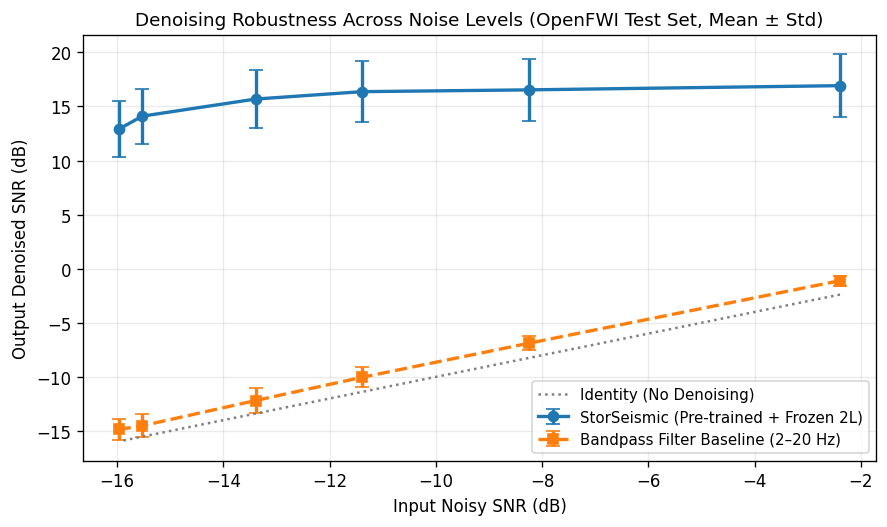

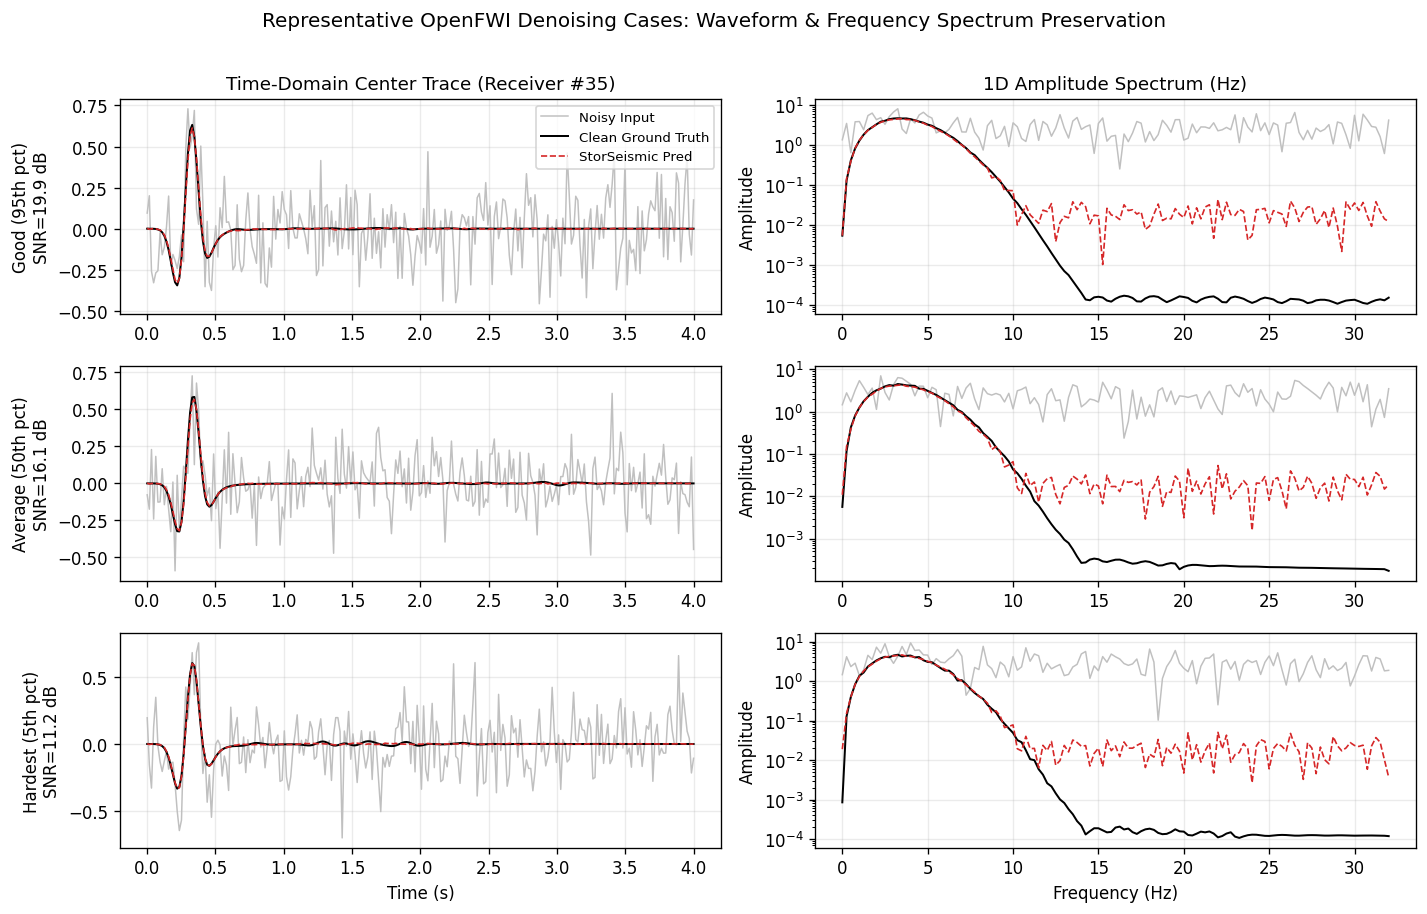

In [4]:
NB3_PRETRAIN_CKPT = os.path.join(NB3_DIR, "storseismic_pretrained_mixed.pt")
NB3_DENOISE_CKPT = os.path.join(NB3_DIR, "storseismic_finetuned_denoise.pt")
NB3_VEL_CKPT = os.path.join(NB3_DIR, "storseismic_finetuned_velpred.pt")

nb3_pretrain = load_weights_safe(StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS).to(device), NB3_PRETRAIN_CKPT)
nb3_denoise = load_weights_safe(StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device), NB3_DENOISE_CKPT)
nb3_vel = load_weights_safe(StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=VEL_DIM).to(device), NB3_VEL_CKPT)

# Verify Mobil field denoising fix
mobil_diag = evaluate_denoise_mobil(nb3_denoise, f_test)
synth_den_diag = evaluate_denoise_openfwi(nb3_denoise, s_test, sigma=0.15)
synth_vel_diag = evaluate_velocity_openfwi(nb3_vel, s_test, v_test_ms)

print("=== nb3 Baseline Verification ===")
print(f"OpenFWI Denoise (sigma=0.15) : Input SNR={synth_den_diag['input_snr_db']:.2f} dB -> Output SNR={synth_den_diag['output_snr_db']:.2f} dB | r={synth_den_diag['corr_r']:.4f}")
print(f"Mobil Field Denoise          : Raw-Denoised Corr (r)={mobil_diag['mobil_corr_r']:.4f} | Removed Energy={mobil_diag['mobil_removed_energy_pct']:.2f}%")
print(f"OpenFWI 1D Velocity          : MAE={synth_vel_diag['vel_mae_ms']:.1f} m/s | R^2={synth_vel_diag['vel_r2']:.4f}")

# --- PLOT 1: SNR Robustness Curve with Error Bars (StorSeismic vs Bandpass vs Identity) ---
sigmas = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]
in_means, ss_means, ss_stds, bp_means, bp_stds = [], [], [], [], []
rng = np.random.default_rng(77)

for sig in sigmas:
    s_in, s_ss, s_bp = [], [], []
    for clean in s_test:
        noisy = normalize_gather(clean + rng.normal(0.0, sig, size=clean.shape)).astype(np.float32)
        with torch.no_grad():
            pred = nb3_denoise(torch.tensor(noisy[None], device=device)).cpu().numpy()[0]
        bp = normalize_gather(bandpass_filter(noisy, low=2.0, high=20.0))
        s_in.append(compute_snr_db(clean, noisy))
        s_ss.append(compute_snr_db(clean, pred))
        s_bp.append(compute_snr_db(clean, bp))
    in_means.append(np.mean(s_in))
    ss_means.append(np.mean(s_ss)); ss_stds.append(np.std(s_ss))
    bp_means.append(np.mean(s_bp)); bp_stds.append(np.std(s_bp))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.errorbar(in_means, ss_means, yerr=ss_stds, marker="o", capsize=4, lw=2, label="StorSeismic (Pre-trained + Frozen 2L)", color="#1f77b4")
ax.errorbar(in_means, bp_means, yerr=bp_stds, marker="s", capsize=4, lw=2, ls="--", label="Bandpass Filter Baseline (2–20 Hz)", color="#ff7f0e")
ax.plot(in_means, in_means, ls=":", color="gray", label="Identity (No Denoising)")
ax.set_xlabel("Input Noisy SNR (dB)")
ax.set_ylabel("Output Denoised SNR (dB)")
ax.set_title("Denoising Robustness Across Noise Levels (OpenFWI Test Set, Mean ± Std)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig1_snr_robustness.png"))
plt.show()

# --- PLOT 2: Good / Average / Failure Qualitative Waveform + Frequency Spectrum ---
rng = np.random.default_rng(99)
per_sample_snrs, noisy_list, pred_list = [], [], []
for clean in s_test:
    noisy = normalize_gather(clean + rng.normal(0.0, 0.20, size=clean.shape)).astype(np.float32)
    with torch.no_grad():
        pred = nb3_denoise(torch.tensor(noisy[None], device=device)).cpu().numpy()[0]
    per_sample_snrs.append(compute_snr_db(clean, pred))
    noisy_list.append(noisy)
    pred_list.append(pred)

order = np.argsort(per_sample_snrs)
pick_idx = [order[int(0.95 * len(order))], order[int(0.50 * len(order))], order[int(0.05 * len(order))]]
pick_labels = ["Good (95th pct)", "Average (50th pct)", "Hardest (5th pct)"]

t_axis = np.linspace(0, 4.0, N_TIME)
freqs = np.fft.rfftfreq(N_TIME, d=1.0 / FS_RESAMPLED)

fig, axes = plt.subplots(3, 2, figsize=(12, 7.5))
for row, (idx, lbl) in enumerate(zip(pick_idx, pick_labels)):
    tr = 35  # center receiver trace
    c_tr = s_test[idx, tr]
    n_tr = noisy_list[idx][tr]
    p_tr = pred_list[idx][tr]
    snr_val = per_sample_snrs[idx]

    axes[row, 0].plot(t_axis, n_tr, color="silver", lw=0.9, label="Noisy Input")
    axes[row, 0].plot(t_axis, c_tr, color="black", lw=1.2, label="Clean Ground Truth")
    axes[row, 0].plot(t_axis, p_tr, color="#d62728", lw=1.0, ls="--", label="StorSeismic Pred")
    axes[row, 0].set_ylabel(f"{lbl}\nSNR={snr_val:.1f} dB")
    if row == 0:
        axes[row, 0].set_title("Time-Domain Center Trace (Receiver #35)")
        axes[row, 0].legend(loc="upper right", fontsize=8)
    if row == 2:
        axes[row, 0].set_xlabel("Time (s)")

    axes[row, 1].semilogy(freqs, np.abs(np.fft.rfft(n_tr)) + 1e-4, color="silver", lw=0.9, label="Noisy")
    axes[row, 1].semilogy(freqs, np.abs(np.fft.rfft(c_tr)) + 1e-4, color="black", lw=1.2, label="Clean")
    axes[row, 1].semilogy(freqs, np.abs(np.fft.rfft(p_tr)) + 1e-4, color="#d62728", lw=1.0, ls="--", label="Pred")
    axes[row, 1].set_ylabel("Amplitude")
    if row == 0:
        axes[row, 1].set_title("1D Amplitude Spectrum (Hz)")
    if row == 2:
        axes[row, 1].set_xlabel("Frequency (Hz)")

plt.suptitle("Representative OpenFWI Denoising Cases: Waveform & Frequency Spectrum Preservation", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig2_qualitative_waveform_spectrum.png"), bbox_inches="tight")
plt.show()


### Additional Baseline Diagnostic: Per-Gather SNR Gain Distribution ($\Delta\text{SNR}$)

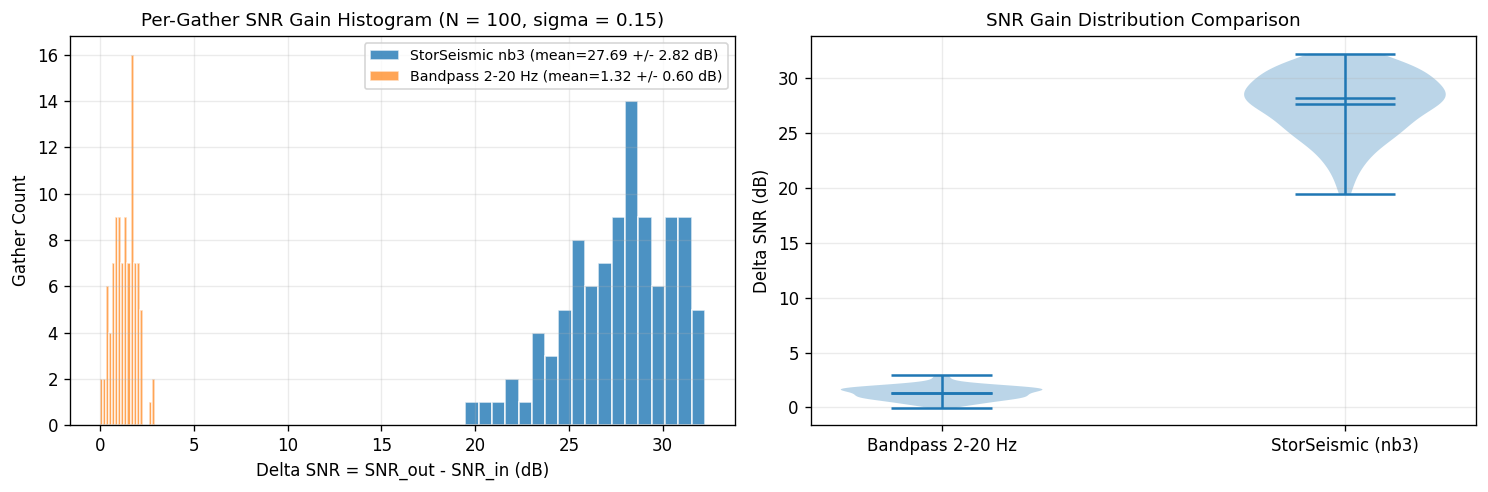

In [5]:
# Per-Gather SNR Gain Distribution (Delta SNR = SNR_out - SNR_in) across all 100 OpenFWI test gathers
rng_dist = np.random.default_rng(77)
gains_ss, gains_bp = [], []
nb3_denoise.eval()
for clean in s_test:
    noisy = normalize_gather(clean + rng_dist.normal(0.0, 0.15, size=clean.shape)).astype(np.float32)
    with torch.no_grad():
        pred = nb3_denoise(torch.tensor(noisy[None], device=device)).cpu().numpy()[0]
    bp = normalize_gather(bandpass_filter(noisy, low=2.0, high=20.0))
    snr_in = compute_snr_db(clean, noisy)
    gains_ss.append(compute_snr_db(clean, pred) - snr_in)
    gains_bp.append(compute_snr_db(clean, bp) - snr_in)

gains_ss = np.array(gains_ss)
gains_bp = np.array(gains_bp)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].hist(gains_ss, bins=18, alpha=0.8, color="#1f77b4", edgecolor="white",
             label=f"StorSeismic nb3 (mean={gains_ss.mean():.2f} +/- {gains_ss.std():.2f} dB)")
axes[0].hist(gains_bp, bins=18, alpha=0.7, color="#ff7f0e", edgecolor="white",
             label=f"Bandpass 2-20 Hz (mean={gains_bp.mean():.2f} +/- {gains_bp.std():.2f} dB)")
axes[0].set_title("Per-Gather SNR Gain Histogram (N = 100, sigma = 0.15)")
axes[0].set_xlabel("Delta SNR = SNR_out - SNR_in (dB)")
axes[0].set_ylabel("Gather Count")
axes[0].legend(fontsize=8.5)

vp = axes[1].violinplot([gains_bp, gains_ss], showmeans=True, showmedians=True)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Bandpass 2-20 Hz", "StorSeismic (nb3)"])
axes[1].set_ylabel("Delta SNR (dB)")
axes[1].set_title("SNR Gain Distribution Comparison")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_b1_snr_gain_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

## 4. Experiment A1 — Pre-Training vs. Training from Scratch (Sample Efficiency Study)
Evaluates whether self-supervised MLM pre-training improves accuracy when only **10%, 25%, 50%, or 100%** of labeled OpenFWI gathers are available for fine-tuning.


[SKIP] Loaded A1 metrics from ./results/nb4_experiments\metrics\a1_sample_efficiency.json


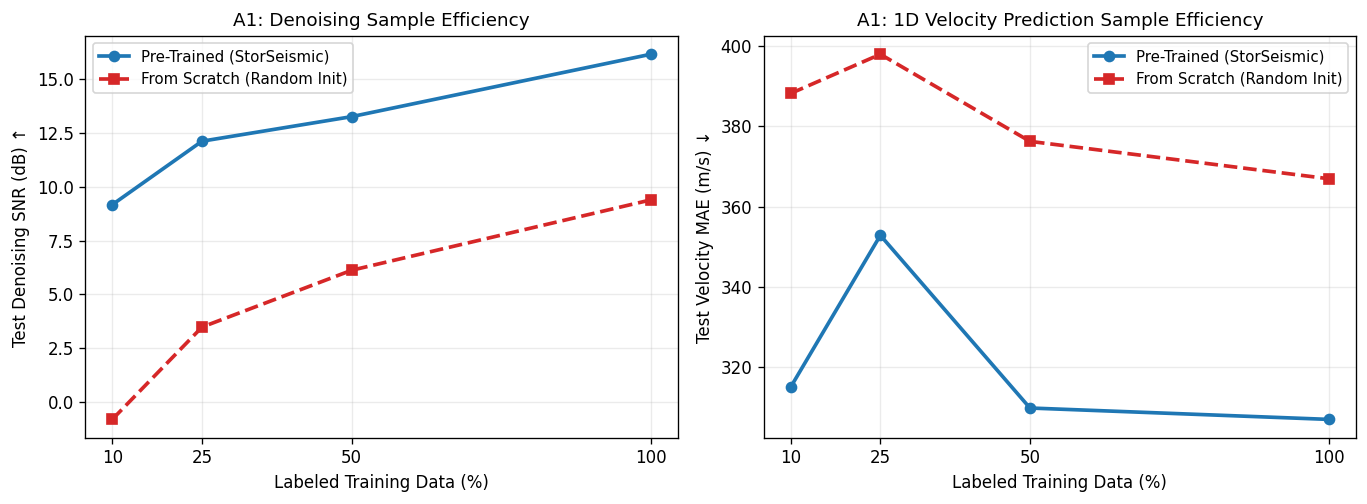

In [6]:
A1_METRICS_PATH = os.path.join(METRICS_DIR, "a1_sample_efficiency.json")
FRACTIONS = [0.10, 0.25, 0.50, 1.00]

if os.path.exists(A1_METRICS_PATH) and (not RUN_TRAINING or not FORCE_RETRAIN):
    a1_results = load_json(A1_METRICS_PATH)
    print(f"[SKIP] Loaded A1 metrics from {A1_METRICS_PATH}")
else:
    a1_results = {"fractions": FRACTIONS, "pretrained": {"den_snr": [], "vel_mae": []}, "scratch": {"den_snr": [], "vel_mae": []}}
    for frac in FRACTIONS:
        n_sub = max(16, int(round(len(s_train) * frac)))
        tag = int(frac * 100)

        # Pre-trained (reuse nb3 at 100% if available)
        if frac == 1.00 and os.path.exists(NB3_DENOISE_CKPT):
            m_den_pt = nb3_denoise
        else:
            m_den_pt = train_or_load_denoise(
                os.path.join(CKPT_DIR, f"a1_den_pt_{tag}pct.pt"), NB3_PRETRAIN_CKPT, s_train[:n_sub], num_freeze=2
            )
        if frac == 1.00 and os.path.exists(NB3_VEL_CKPT):
            m_vel_pt = nb3_vel
        else:
            m_vel_pt = train_or_load_vel(
                os.path.join(CKPT_DIR, f"a1_vel_pt_{tag}pct.pt"), NB3_PRETRAIN_CKPT, s_train[:n_sub], v_train[:n_sub], num_freeze=2
            )

        # From Scratch (random init, num_freeze=0)
        m_den_sc = train_or_load_denoise(
            os.path.join(CKPT_DIR, f"a1_den_sc_{tag}pct.pt"), None, s_train[:n_sub], num_freeze=0
        )
        m_vel_sc = train_or_load_vel(
            os.path.join(CKPT_DIR, f"a1_vel_sc_{tag}pct.pt"), None, s_train[:n_sub], v_train[:n_sub], num_freeze=0
        )

        a1_results["pretrained"]["den_snr"].append(evaluate_denoise_openfwi(m_den_pt, s_test)["output_snr_db"])
        a1_results["pretrained"]["vel_mae"].append(evaluate_velocity_openfwi(m_vel_pt, s_test, v_test_ms)["vel_mae_ms"])
        a1_results["scratch"]["den_snr"].append(evaluate_denoise_openfwi(m_den_sc, s_test)["output_snr_db"])
        a1_results["scratch"]["vel_mae"].append(evaluate_velocity_openfwi(m_vel_sc, s_test, v_test_ms)["vel_mae_ms"])

    save_json(a1_results, A1_METRICS_PATH)
    print(f"Saved A1 metrics to {A1_METRICS_PATH}")

# Plot A1
pcts = [int(f * 100) for f in a1_results["fractions"]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

ax1.plot(pcts, a1_results["pretrained"]["den_snr"], marker="o", lw=2.2, label="Pre-Trained (StorSeismic)", color="#1f77b4")
ax1.plot(pcts, a1_results["scratch"]["den_snr"], marker="s", lw=2.2, ls="--", label="From Scratch (Random Init)", color="#d62728")
ax1.set_xlabel("Labeled Training Data (%)")
ax1.set_ylabel("Test Denoising SNR (dB) ↑")
ax1.set_title("A1: Denoising Sample Efficiency")
ax1.set_xticks(pcts)
ax1.legend()

ax2.plot(pcts, a1_results["pretrained"]["vel_mae"], marker="o", lw=2.2, label="Pre-Trained (StorSeismic)", color="#1f77b4")
ax2.plot(pcts, a1_results["scratch"]["vel_mae"], marker="s", lw=2.2, ls="--", label="From Scratch (Random Init)", color="#d62728")
ax2.set_xlabel("Labeled Training Data (%)")
ax2.set_ylabel("Test Velocity MAE (m/s) ↓")
ax2.set_title("A1: 1D Velocity Prediction Sample Efficiency")
ax2.set_xticks(pcts)
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig3_a1_sample_efficiency.png"))
plt.show()


### Additional A1 Visual Comparison: Power of Pre-Training at 10% Labels (40 Gathers)

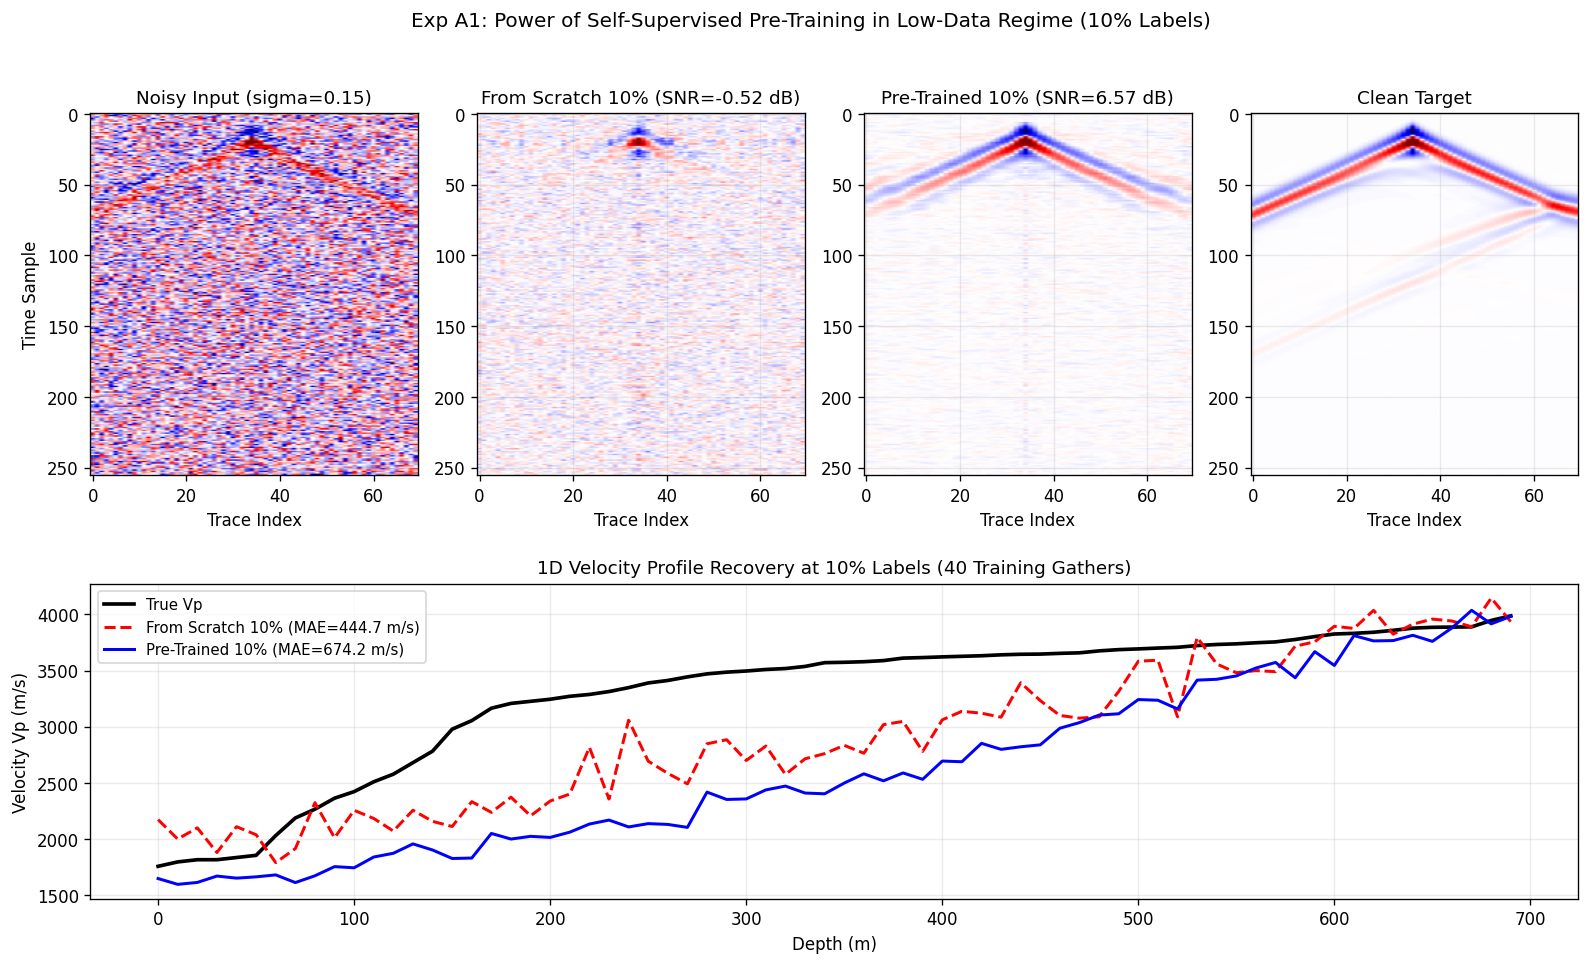

In [7]:
# Load 10%-label checkpoints (From Scratch vs. Pre-Trained) for Denoising and Velocity
m_den_sc10 = load_weights_safe(
    StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device),
    os.path.join(CKPT_DIR, "a1_den_sc_10pct.pt"),
)
m_den_pt10 = load_weights_safe(
    StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device),
    os.path.join(CKPT_DIR, "a1_den_pt_10pct.pt"),
)
m_vel_sc10 = load_weights_safe(
    StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=VEL_DIM).to(device),
    os.path.join(CKPT_DIR, "a1_vel_sc_10pct.pt"),
)
m_vel_pt10 = load_weights_safe(
    StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=VEL_DIM).to(device),
    os.path.join(CKPT_DIR, "a1_vel_pt_10pct.pt"),
)
for m in (m_den_sc10, m_den_pt10, m_vel_sc10, m_vel_pt10):
    m.eval()

sample_i = 10
clean_g = s_test[sample_i]
rng_a1 = np.random.default_rng(42)
noisy_g = normalize_gather(clean_g + rng_a1.normal(0.0, 0.15, size=clean_g.shape)).astype(np.float32)

with torch.no_grad():
    pred_den_sc10 = m_den_sc10(torch.tensor(noisy_g[None], device=device)).cpu().numpy()[0]
    pred_den_pt10 = m_den_pt10(torch.tensor(noisy_g[None], device=device)).cpu().numpy()[0]
    pred_vel_sc10 = m_vel_sc10(torch.tensor(clean_g[None], device=device))[0, 0, :].cpu().numpy() * (VEL_MAX - VEL_MIN) + VEL_MIN
    pred_vel_pt10 = m_vel_pt10(torch.tensor(clean_g[None], device=device))[0, 0, :].cpu().numpy() * (VEL_MAX - VEL_MIN) + VEL_MIN

snr_sc10 = compute_snr_db(clean_g, pred_den_sc10)
snr_pt10 = compute_snr_db(clean_g, pred_den_pt10)
mae_sc10 = np.mean(np.abs(pred_vel_sc10 - v_test_ms[sample_i]))
mae_pt10 = np.mean(np.abs(pred_vel_pt10 - v_test_ms[sample_i]))

fig = plt.figure(figsize=(16, 8.5))
gs = fig.add_gridspec(2, 4, height_ratios=[1.15, 1.0], hspace=0.32, wspace=0.18)

den_panels = [
    ("Noisy Input (sigma=0.15)", noisy_g),
    (f"From Scratch 10% (SNR={snr_sc10:.2f} dB)", pred_den_sc10),
    (f"Pre-Trained 10% (SNR={snr_pt10:.2f} dB)", pred_den_pt10),
    ("Clean Target", clean_g),
]
for j, (title, g) in enumerate(den_panels):
    ax = fig.add_subplot(gs[0, j])
    ax.imshow(g.T, aspect="auto", cmap="seismic", vmin=-0.5, vmax=0.5)
    ax.set_title(title)
    ax.set_xlabel("Trace Index")
    if j == 0:
        ax.set_ylabel("Time Sample")

ax_vel = fig.add_subplot(gs[1, :])
depth_m = np.arange(VEL_DIM) * 10.0
ax_vel.plot(depth_m, v_test_ms[sample_i], "k-", lw=2.2, label="True Vp")
ax_vel.plot(depth_m, pred_vel_sc10, "r--", lw=1.8, label=f"From Scratch 10% (MAE={mae_sc10:.1f} m/s)")
ax_vel.plot(depth_m, pred_vel_pt10, "b-", lw=1.8, label=f"Pre-Trained 10% (MAE={mae_pt10:.1f} m/s)")
ax_vel.set_title("1D Velocity Profile Recovery at 10% Labels (40 Training Gathers)")
ax_vel.set_xlabel("Depth (m)")
ax_vel.set_ylabel("Velocity Vp (m/s)")
ax_vel.legend()

fig.suptitle("Exp A1: Power of Self-Supervised Pre-Training in Low-Data Regime (10% Labels)", y=0.98)
plt.savefig(os.path.join(FIG_DIR, "fig_a1_10pct_visual_comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

## 5. Experiment A2 — Partial Layer Freezing Sweep (Section 6.3)
Sweeps `num_freeze` $\in \{0, 1, 2, 3, 4\}$ (where `0` = all unfrozen, `4` = linear probe of head only) to quantify the trade-off between **synthetic fit** and **Mobil field generalization**.


[SKIP] Loaded A2 metrics from ./results/nb4_experiments\metrics\a2_freezing_sweep.json


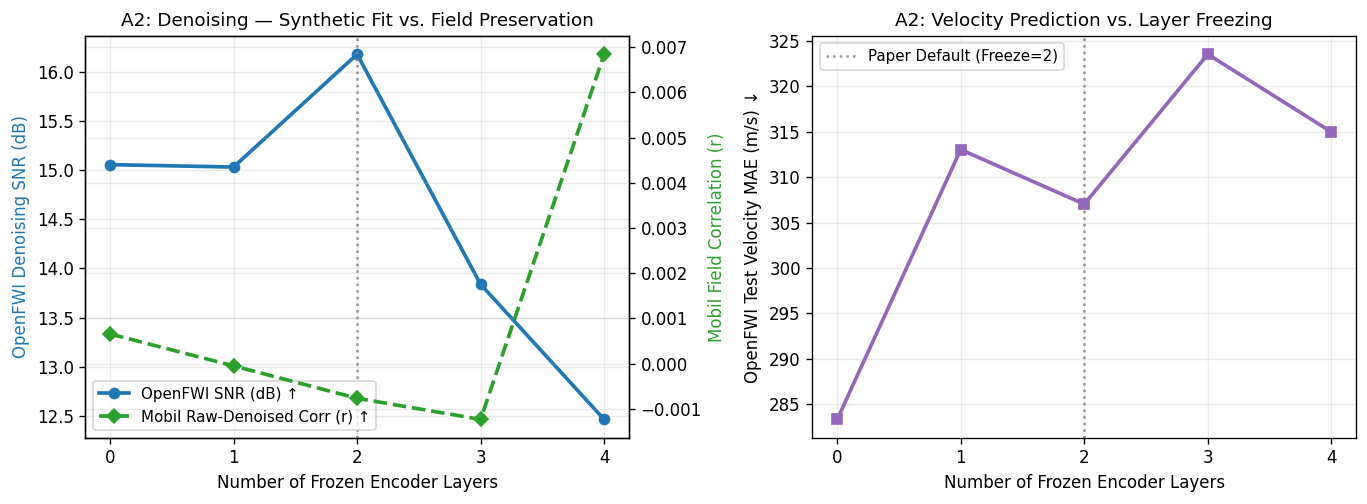

In [8]:
A2_METRICS_PATH = os.path.join(METRICS_DIR, "a2_freezing_sweep.json")
FREEZE_LEVELS = [0, 1, 2, 3, 4]

if os.path.exists(A2_METRICS_PATH) and (not RUN_TRAINING or not FORCE_RETRAIN):
    a2_results = load_json(A2_METRICS_PATH)
    print(f"[SKIP] Loaded A2 metrics from {A2_METRICS_PATH}")
else:
    a2_results = {"freeze_levels": FREEZE_LEVELS, "den_snr": [], "vel_mae": [], "mobil_corr": [], "mobil_rem_e": []}
    for nf in FREEZE_LEVELS:
        if nf == 2 and os.path.exists(NB3_DENOISE_CKPT):
            m_den = nb3_denoise
        else:
            m_den = train_or_load_denoise(
                os.path.join(CKPT_DIR, f"a2_den_freeze{nf}.pt"), NB3_PRETRAIN_CKPT, s_train, num_freeze=nf
            )
        if nf == 2 and os.path.exists(NB3_VEL_CKPT):
            m_vel = nb3_vel
        else:
            m_vel = train_or_load_vel(
                os.path.join(CKPT_DIR, f"a2_vel_freeze{nf}.pt"), NB3_PRETRAIN_CKPT, s_train, v_train, num_freeze=nf
            )

        a2_results["den_snr"].append(evaluate_denoise_openfwi(m_den, s_test)["output_snr_db"])
        a2_results["vel_mae"].append(evaluate_velocity_openfwi(m_vel, s_test, v_test_ms)["vel_mae_ms"])
        md = evaluate_denoise_mobil(m_den, f_test)
        a2_results["mobil_corr"].append(md["mobil_corr_r"])
        a2_results["mobil_rem_e"].append(md["mobil_removed_energy_pct"])

    save_json(a2_results, A2_METRICS_PATH)
    print(f"Saved A2 metrics to {A2_METRICS_PATH}")

# Plot A2
fl = a2_results["freeze_levels"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))

ax1_t = ax1.twinx()
l1 = ax1.plot(fl, a2_results["den_snr"], marker="o", lw=2.2, color="#1f77b4", label="OpenFWI SNR (dB) ↑")
l2 = ax1_t.plot(fl, a2_results["mobil_corr"], marker="D", lw=2.2, ls="--", color="#2ca02c", label="Mobil Raw-Denoised Corr (r) ↑")
ax1.axvline(2, color="gray", ls=":", alpha=0.8)
ax1.set_xlabel("Number of Frozen Encoder Layers")
ax1.set_ylabel("OpenFWI Denoising SNR (dB)", color="#1f77b4")
ax1_t.set_ylabel("Mobil Field Correlation (r)", color="#2ca02c")
ax1.set_xticks(fl)
ax1.set_title("A2: Denoising — Synthetic Fit vs. Field Preservation")
lines = l1 + l2
ax1.legend(lines, [l.get_label() for l in lines], loc="lower left")

ax2.plot(fl, a2_results["vel_mae"], marker="s", lw=2.2, color="#9467bd")
ax2.axvline(2, color="gray", ls=":", alpha=0.8, label="Paper Default (Freeze=2)")
ax2.set_xlabel("Number of Frozen Encoder Layers")
ax2.set_ylabel("OpenFWI Test Velocity MAE (m/s) ↓")
ax2.set_xticks(fl)
ax2.set_title("A2: Velocity Prediction vs. Layer Freezing")
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig4_a2_freezing_sweep.png"))
plt.show()


### Additional A2 Visual Comparison: Freezing Sweep on Mobil Field Gather

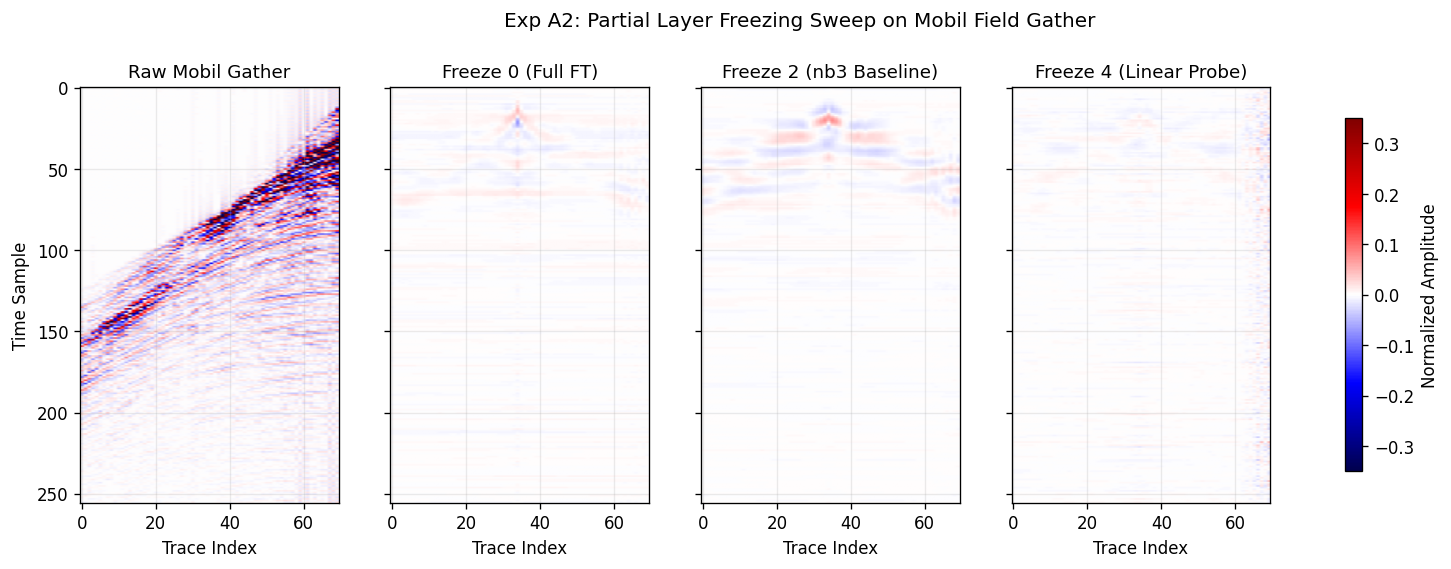

In [9]:
# 1x4 panel on unseen Mobil field gather: Raw | Freeze 0 | Freeze 2 (nb3) | Freeze 4
m_f0 = load_weights_safe(
    StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device),
    os.path.join(CKPT_DIR, "a2_den_freeze0.pt"),
)
m_f4 = load_weights_safe(
    StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device),
    os.path.join(CKPT_DIR, "a2_den_freeze4.pt"),
)
m_f0.eval()
nb3_denoise.eval()
m_f4.eval()

raw_mob_a2 = f_test[5]
with torch.no_grad():
    x_mob_a2 = torch.tensor(raw_mob_a2[None], device=device)
    pred_f0 = m_f0(x_mob_a2).cpu().numpy()[0]
    pred_f2 = nb3_denoise(x_mob_a2).cpu().numpy()[0]
    pred_f4 = m_f4(x_mob_a2).cpu().numpy()[0]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), sharex=True, sharey=True)
a2_panels = [
    ("Raw Mobil Gather", raw_mob_a2),
    ("Freeze 0 (Full FT)", pred_f0),
    ("Freeze 2 (nb3 Baseline)", pred_f2),
    ("Freeze 4 (Linear Probe)", pred_f4),
]
for ax, (title, g) in zip(axes, a2_panels):
    im = ax.imshow(g.T, aspect="auto", cmap="seismic", vmin=-0.35, vmax=0.35)
    ax.set_title(title)
    ax.set_xlabel("Trace Index")
axes[0].set_ylabel("Time Sample")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized Amplitude", shrink=0.85)
fig.suptitle("Exp A2: Partial Layer Freezing Sweep on Mobil Field Gather", y=1.02)
plt.savefig(os.path.join(FIG_DIR, "fig_a2_freezing_visual_gathers.png"), dpi=300, bbox_inches="tight")
plt.show()

## 6. Experiment A3 — Pre-Training Data Mix Ablation (Section 6.2)
Compares three self-supervised pre-training regimes: **100% OpenFWI**, **50/50 Mixed (reused from `nb3`)**, and **100% Mobil**, followed by identical fine-tuning (`num_freeze=2`).


[SKIP] Loaded A3 metrics from ./results/nb4_experiments\metrics\a3_data_mix.json


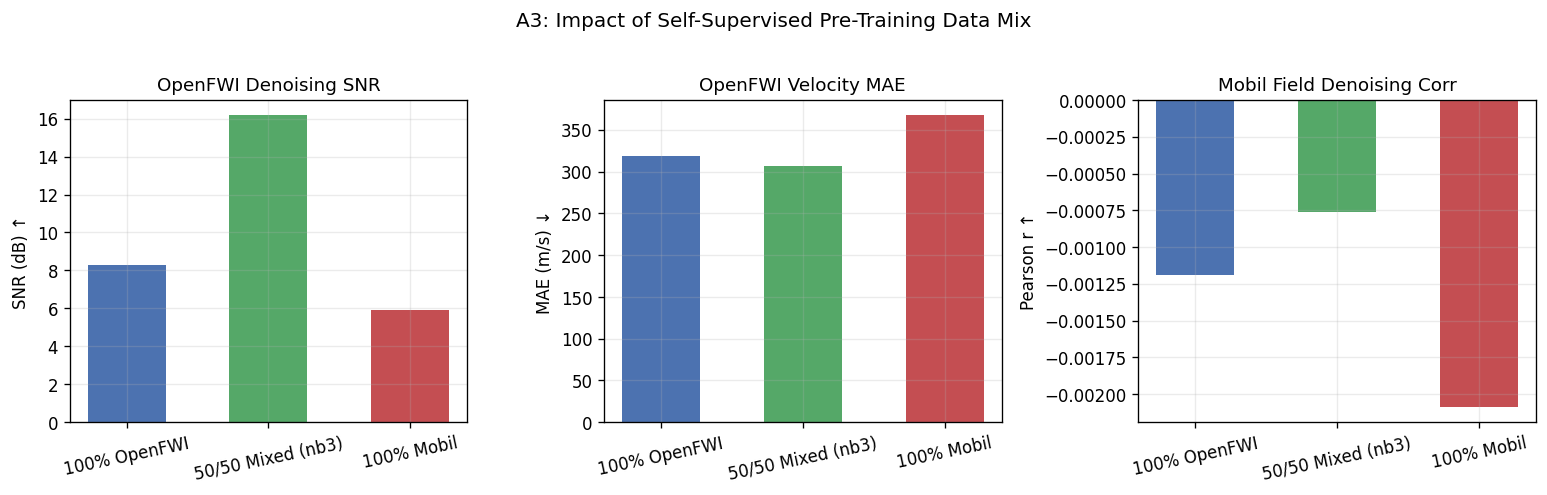

In [10]:
A3_METRICS_PATH = os.path.join(METRICS_DIR, "a3_data_mix.json")
MIX_NAMES = ["100% OpenFWI", "50/50 Mixed (nb3)", "100% Mobil"]

if os.path.exists(A3_METRICS_PATH) and (not RUN_TRAINING or not FORCE_RETRAIN):
    a3_results = load_json(A3_METRICS_PATH)
    print(f"[SKIP] Loaded A3 metrics from {A3_METRICS_PATH}")
else:
    a3_results = {"regimes": MIX_NAMES, "den_snr": [], "vel_mae": [], "mobil_corr": []}

    # 1. 100% OpenFWI pre-training
    pt_synth_ckpt = os.path.join(CKPT_DIR, "a3_pt_100synth.pt")
    train_or_load_pretrain(pt_synth_ckpt, s_train, s_test)
    m_den_s = train_or_load_denoise(os.path.join(CKPT_DIR, "a3_den_100synth.pt"), pt_synth_ckpt, s_train, num_freeze=2)
    m_vel_s = train_or_load_vel(os.path.join(CKPT_DIR, "a3_vel_100synth.pt"), pt_synth_ckpt, s_train, v_train, num_freeze=2)

    # 2. 50/50 Mixed (reuse nb3)
    m_den_m, m_vel_m = nb3_denoise, nb3_vel

    # 3. 100% Mobil pre-training
    pt_field_ckpt = os.path.join(CKPT_DIR, "a3_pt_100mobil.pt")
    train_or_load_pretrain(pt_field_ckpt, f_train, f_test)
    m_den_f = train_or_load_denoise(os.path.join(CKPT_DIR, "a3_den_100mobil.pt"), pt_field_ckpt, s_train, num_freeze=2)
    m_vel_f = train_or_load_vel(os.path.join(CKPT_DIR, "a3_vel_100mobil.pt"), pt_field_ckpt, s_train, v_train, num_freeze=2)

    for md_model, mv_model in [(m_den_s, m_vel_s), (m_den_m, m_vel_m), (m_den_f, m_vel_f)]:
        a3_results["den_snr"].append(evaluate_denoise_openfwi(md_model, s_test)["output_snr_db"])
        a3_results["vel_mae"].append(evaluate_velocity_openfwi(mv_model, s_test, v_test_ms)["vel_mae_ms"])
        a3_results["mobil_corr"].append(evaluate_denoise_mobil(md_model, f_test)["mobil_corr_r"])

    save_json(a3_results, A3_METRICS_PATH)
    print(f"Saved A3 metrics to {A3_METRICS_PATH}")

# Plot A3
x = np.arange(len(MIX_NAMES))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
colors = ["#4c72b0", "#55a868", "#c44e52"]

axes[0].bar(x, a3_results["den_snr"], color=colors, width=0.55)
axes[0].set_xticks(x); axes[0].set_xticklabels(MIX_NAMES, rotation=12)
axes[0].set_ylabel("SNR (dB) ↑"); axes[0].set_title("OpenFWI Denoising SNR")

axes[1].bar(x, a3_results["vel_mae"], color=colors, width=0.55)
axes[1].set_xticks(x); axes[1].set_xticklabels(MIX_NAMES, rotation=12)
axes[1].set_ylabel("MAE (m/s) ↓"); axes[1].set_title("OpenFWI Velocity MAE")

axes[2].bar(x, a3_results["mobil_corr"], color=colors, width=0.55)
axes[2].set_xticks(x); axes[2].set_xticklabels(MIX_NAMES, rotation=12)
axes[2].set_ylabel("Pearson r ↑"); axes[2].set_title("Mobil Field Denoising Corr")

plt.suptitle("A3: Impact of Self-Supervised Pre-Training Data Mix", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig5_a3_data_mix.png"), bbox_inches="tight")
plt.show()


### Additional A3 Visual Contrast: Pre-Training Data Mix on Mobil Field Data

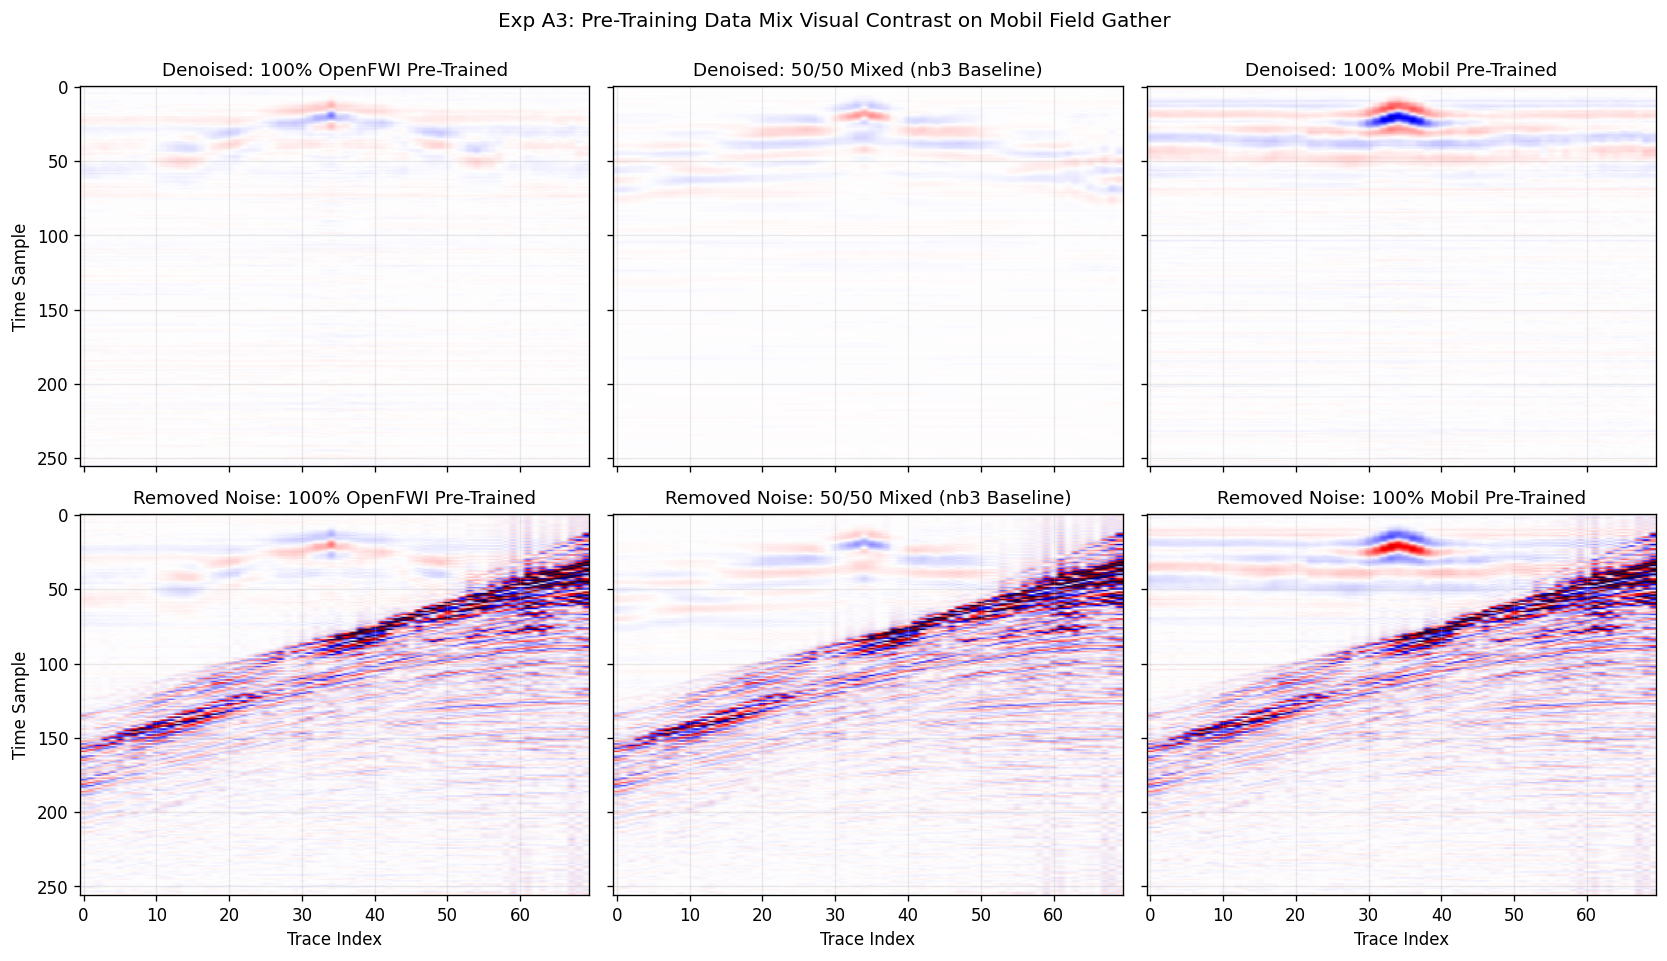

In [11]:
# Load A3 models and compare denoised & removed-noise gathers on unseen Mobil field shot
m_a3_synth = load_weights_safe(
    StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device),
    os.path.join(CKPT_DIR, "a3_den_100synth.pt"),
)
m_a3_mobil = load_weights_safe(
    StorSeismic(N_TIME, HIDDEN_DIM, NUM_LAYERS, NUM_HEADS, out_dim=N_TIME).to(device),
    os.path.join(CKPT_DIR, "a3_den_100mobil.pt"),
)
m_a3_synth.eval()
nb3_denoise.eval()
m_a3_mobil.eval()

mobil_sample_idx = 5
raw_mob = f_test[mobil_sample_idx]
with torch.no_grad():
    x_mob = torch.tensor(raw_mob[None], device=device)
    out_100synth = m_a3_synth(x_mob).cpu().numpy()[0]
    out_50mix = nb3_denoise(x_mob).cpu().numpy()[0]
    out_100mobil = m_a3_mobil(x_mob).cpu().numpy()[0]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
a3_cols = [
    ("100% OpenFWI Pre-Trained", out_100synth),
    ("50/50 Mixed (nb3 Baseline)", out_50mix),
    ("100% Mobil Pre-Trained", out_100mobil),
]
for col_idx, (title, pred) in enumerate(a3_cols):
    axes[0, col_idx].imshow(pred.T, aspect="auto", cmap="seismic", vmin=-0.35, vmax=0.35)
    axes[0, col_idx].set_title(f"Denoised: {title}")
    axes[1, col_idx].imshow((raw_mob - pred).T, aspect="auto", cmap="seismic", vmin=-0.35, vmax=0.35)
    axes[1, col_idx].set_title(f"Removed Noise: {title}")
    axes[1, col_idx].set_xlabel("Trace Index")
axes[0, 0].set_ylabel("Time Sample")
axes[1, 0].set_ylabel("Time Sample")
fig.suptitle("Exp A3: Pre-Training Data Mix Visual Contrast on Mobil Field Gather", y=0.995)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_a3_datamix_visual_gathers.png"), dpi=300, bbox_inches="tight")
plt.show()

## 7. Experiment A4 — Model Capacity & Parameter Efficiency Scaling (Section 6.1)
Benchmarks **`BERT_TINY`** ($L=2, H=128, A=2$), **`BERT_MINI`** ($L=4, H=256, A=4$, reused from `nb3`), and **`BERT_SMALL`** ($L=4, H=512, A=8$) — plotting parameter efficiency (log-scale parameters vs. performance) and inference latency.

[SKIP] Loaded A4 metrics from ./results/nb4_experiments\metrics\a5_model_scaling.json


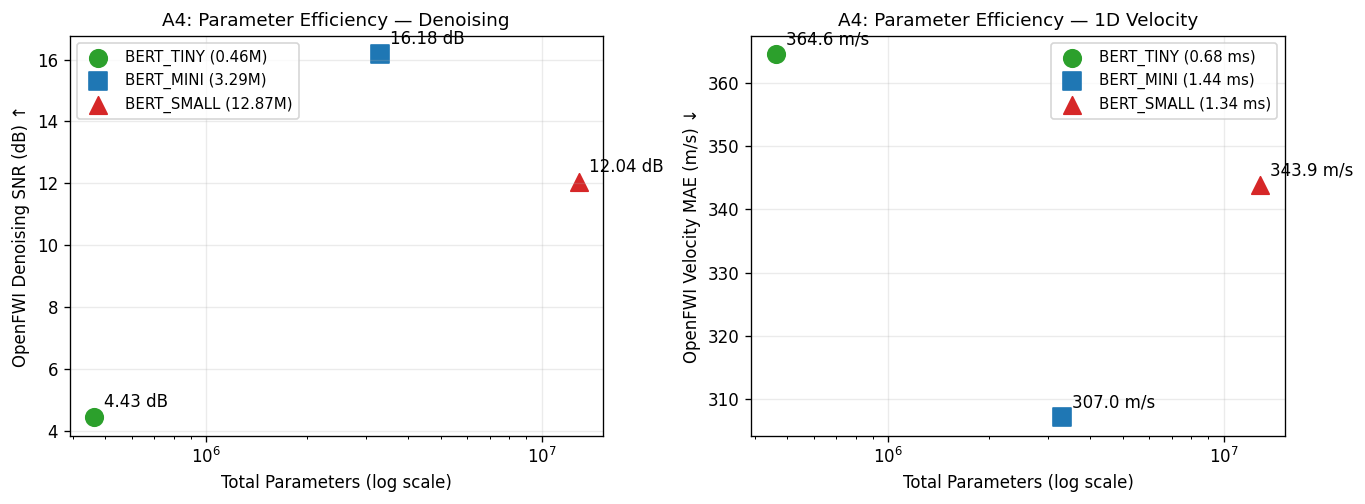

In [12]:
A5_METRICS_PATH = os.path.join(METRICS_DIR, "a5_model_scaling.json")
MODEL_SPECS = [
    {"name": "BERT_TINY",  "L": 2, "H": 128, "A": 2, "freeze": 1},
    {"name": "BERT_MINI",  "L": 4, "H": 256, "A": 4, "freeze": 2},
    {"name": "BERT_SMALL", "L": 4, "H": 512, "A": 8, "freeze": 2},
]

def measure_latency_ms(model, sample_gather, runs=30):
    model.eval()
    inp = torch.tensor(sample_gather[None], device=device)
    with torch.no_grad():
        for _ in range(5):
            _ = model(inp)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(runs):
            _ = model(inp)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
    return float((time.perf_counter() - t0) * 1000.0 / runs)

if os.path.exists(A5_METRICS_PATH) and (not RUN_TRAINING or not FORCE_RETRAIN):
    a5_results = load_json(A5_METRICS_PATH)
    print(f"[SKIP] Loaded A4 metrics from {A5_METRICS_PATH}")
else:
    a5_results = {"models": [], "params": [], "den_snr": [], "vel_mae": [], "latency_ms": []}
    mixed_tr = np.concatenate([s_train, f_train], axis=0)
    mixed_te = np.concatenate([s_test, f_test], axis=0)

    for spec in MODEL_SPECS:
        name, L, H, A, nf = spec["name"], spec["L"], spec["H"], spec["A"], spec["freeze"]
        if name == "BERT_MINI" and os.path.exists(NB3_DENOISE_CKPT) and os.path.exists(NB3_VEL_CKPT):
            m_den, m_vel = nb3_denoise, nb3_vel
        else:
            pt_ckpt = os.path.join(CKPT_DIR, f"a5_pt_{name.lower()}.pt")
            train_or_load_pretrain(pt_ckpt, mixed_tr, mixed_te, hidden_dim=H, num_layers=L, num_heads=A)
            m_den = train_or_load_denoise(
                os.path.join(CKPT_DIR, f"a5_den_{name.lower()}.pt"), pt_ckpt, s_train,
                num_freeze=nf, hidden_dim=H, num_layers=L, num_heads=A
            )
            m_vel = train_or_load_vel(
                os.path.join(CKPT_DIR, f"a5_vel_{name.lower()}.pt"), pt_ckpt, s_train, v_train,
                num_freeze=nf, hidden_dim=H, num_layers=L, num_heads=A
            )

        total_params, _ = m_den.count_params()
        a5_results["models"].append(name)
        a5_results["params"].append(total_params)
        a5_results["den_snr"].append(evaluate_denoise_openfwi(m_den, s_test)["output_snr_db"])
        a5_results["vel_mae"].append(evaluate_velocity_openfwi(m_vel, s_test, v_test_ms)["vel_mae_ms"])
        a5_results["latency_ms"].append(measure_latency_ms(m_den, s_test[0]))

    save_json(a5_results, A5_METRICS_PATH)
    print(f"Saved A4 metrics to {A5_METRICS_PATH}")

# Plot A5 (Report-Inspired Parameter Efficiency Trade-off)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
markers = ["o", "s", "^"]
colors = ["#2ca02c", "#1f77b4", "#d62728"]

for i, name in enumerate(a5_results["models"]):
    p = a5_results["params"][i]
    ax1.scatter(p, a5_results["den_snr"][i], s=110, marker=markers[i], color=colors[i], label=f"{name} ({p/1e6:.2f}M)")
    ax1.annotate(f"{a5_results['den_snr'][i]:.2f} dB", (p, a5_results["den_snr"][i]), textcoords="offset points", xytext=(6, 6))
    ax2.scatter(p, a5_results["vel_mae"][i], s=110, marker=markers[i], color=colors[i], label=f"{name} ({a5_results['latency_ms'][i]:.2f} ms)")
    ax2.annotate(f"{a5_results['vel_mae'][i]:.1f} m/s", (p, a5_results["vel_mae"][i]), textcoords="offset points", xytext=(6, 6))

for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_xlabel("Total Parameters (log scale)")
    ax.legend()

ax1.set_ylabel("OpenFWI Denoising SNR (dB) ↑")
ax1.set_title("A4: Parameter Efficiency — Denoising")
ax2.set_ylabel("OpenFWI Velocity MAE (m/s) ↓")
ax2.set_title("A4: Parameter Efficiency — 1D Velocity")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig6_a5_parameter_efficiency.png"))
plt.show()

## 8. Experiment B1 — Zero-Shot Dead-Trace Interpolation on Mobil Field Data
Uses the Stage 1 pre-trained MLM backbone (`nb3`) **without any fine-tuning** to reconstruct missing traces on unseen Mobil field shot gathers under two realistic field scenarios:
1. **Random 20% Dead Traces** (e.g., faulty hydrophones)
2. **Contiguous 5-Trace Gap** (e.g., obstacle/streamer dropout)

Benchmarked against standard **1D Linear** and **Cubic Spline** trace interpolation.

B1 Zero-Shot Mobil Interpolation SNR (dB) on Masked Traces:
{
  "random20": {
    "linear": -2.705638155313433,
    "cubic": -5.163347878572869,
    "storseismic": 0.08806663540473803
  },
  "gap5": {
    "linear": -2.6575343016844353,
    "cubic": -9.981873102352353,
    "storseismic": -0.10641092612670526
  }
}


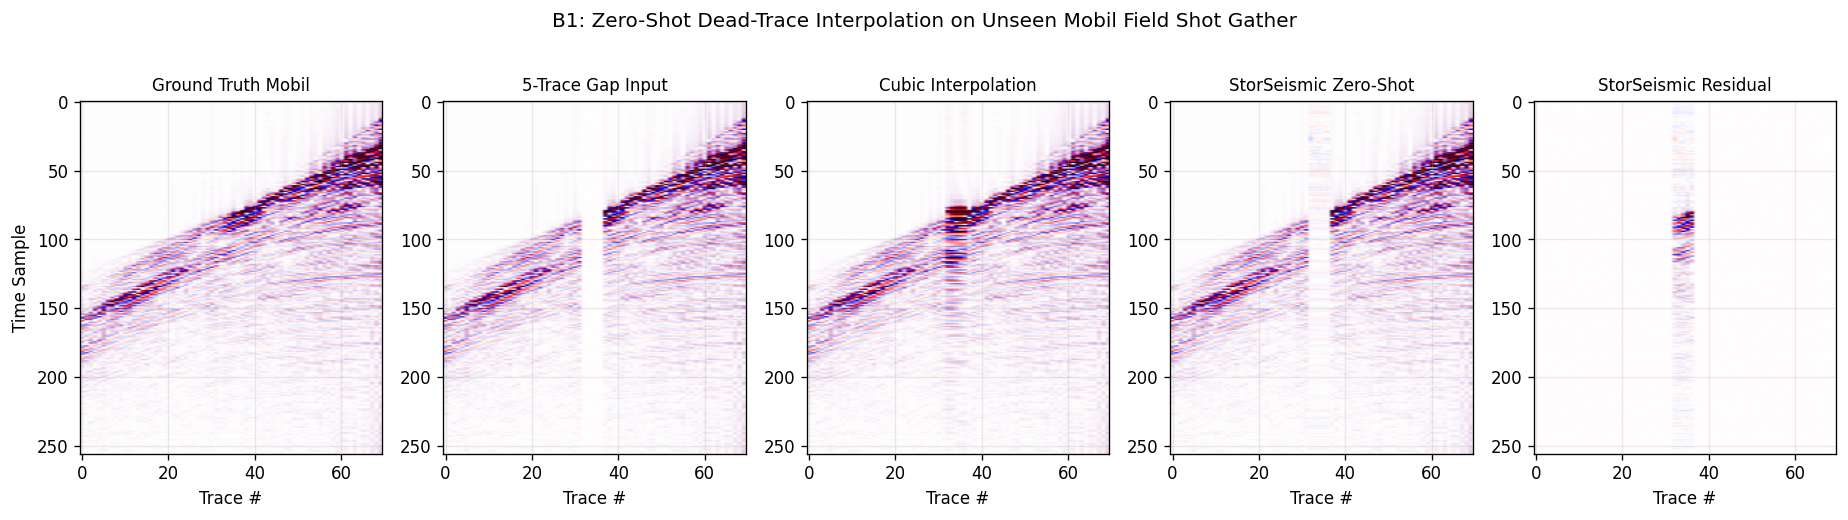

In [13]:
B2_METRICS_PATH = os.path.join(METRICS_DIR, "b2_interpolation.json")

def classical_trace_interp(gather, mask_idx, kind="cubic"):
    n_tr, n_t = gather.shape
    valid_idx = np.setdiff1d(np.arange(n_tr), mask_idx)
    out = gather.copy()
    f_interp = interp1d(valid_idx, gather[valid_idx, :], kind=kind, axis=0, fill_value="extrapolate")
    out[mask_idx, :] = f_interp(mask_idx)
    return out

@torch.no_grad()
def storseismic_zeroshot_interp(model, gather, mask_idx):
    model.eval()
    x = gather.copy()
    # Replace dead traces with low-amplitude Gaussian noise (matching MLM pre-training token)
    rng = np.random.default_rng(42)
    for m in mask_idx:
        x[m] = rng.normal(0.0, 0.3, size=x.shape[1]).astype(np.float32)
    pred = model(torch.tensor(x[None], device=device)).cpu().numpy()[0]
    out = gather.copy()
    out[mask_idx, :] = pred[mask_idx, :]
    return out

def eval_interp_scenario(gathers, scenario="random20"):
    rng = np.random.default_rng(2026)
    res = {"linear": [], "cubic": [], "storseismic": []}
    for g in gathers:
        if scenario == "random20":
            # Avoid boundary traces 0 and 69 for fair spline comparison
            mask_idx = rng.choice(np.arange(1, N_TRACES - 1), size=14, replace=False)
        else:
            mask_idx = np.arange(32, 37)  # 5-trace contiguous gap in center

        gt_m = g[mask_idx]
        lin_m = classical_trace_interp(g, mask_idx, "linear")[mask_idx]
        cub_m = classical_trace_interp(g, mask_idx, "cubic")[mask_idx]
        ss_m = storseismic_zeroshot_interp(nb3_pretrain, g, mask_idx)[mask_idx]

        res["linear"].append(compute_snr_db(gt_m, lin_m))
        res["cubic"].append(compute_snr_db(gt_m, cub_m))
        res["storseismic"].append(compute_snr_db(gt_m, ss_m))
    return {k: float(np.mean(v)) for k, v in res.items()}

b2_results = {
    "random20": eval_interp_scenario(f_test, "random20"),
    "gap5": eval_interp_scenario(f_test, "gap5"),
}
save_json(b2_results, B2_METRICS_PATH)
print("B1 Zero-Shot Mobil Interpolation SNR (dB) on Masked Traces:")
print(json.dumps(b2_results, indent=2))

# Plot B2: Visual Gather Comparison (5-Trace Contiguous Gap) + Bar Chart
sample_g = f_test[10]
gap_idx = np.arange(32, 37)
masked_vis = sample_g.copy(); masked_vis[gap_idx, :] = 0.0
cub_vis = classical_trace_interp(sample_g, gap_idx, "cubic")
ss_vis = storseismic_zeroshot_interp(nb3_pretrain, sample_g, gap_idx)

fig, axes = plt.subplots(1, 5, figsize=(15.5, 4.2))
vmax = 0.35
panels = [
    ("Ground Truth Mobil", sample_g.T),
    ("5-Trace Gap Input", masked_vis.T),
    ("Cubic Interpolation", cub_vis.T),
    ("StorSeismic Zero-Shot", ss_vis.T),
    ("StorSeismic Residual", (sample_g - ss_vis).T),
]
for ax, (title, img) in zip(axes, panels):
    ax.imshow(img, aspect="auto", cmap="seismic", vmin=-vmax, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Trace #")
axes[0].set_ylabel("Time Sample")
plt.suptitle("B1: Zero-Shot Dead-Trace Interpolation on Unseen Mobil Field Shot Gather", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig7_b2_mobil_interpolation.png"), bbox_inches="tight")
plt.show()

## 9. Experiment B2 — Self-Attention Map Interpretability Across Layers
Extracts the $70 \times 70$ receiver-to-receiver self-attention matrices across **Layers 1–4** of the pre-trained `StorSeismic` model for an unseen **Mobil** gather and an **OpenFWI** gather, plus quantifies the **Local Diagonal Concentration** (fraction of attention within $\pm 5$ neighboring receivers).

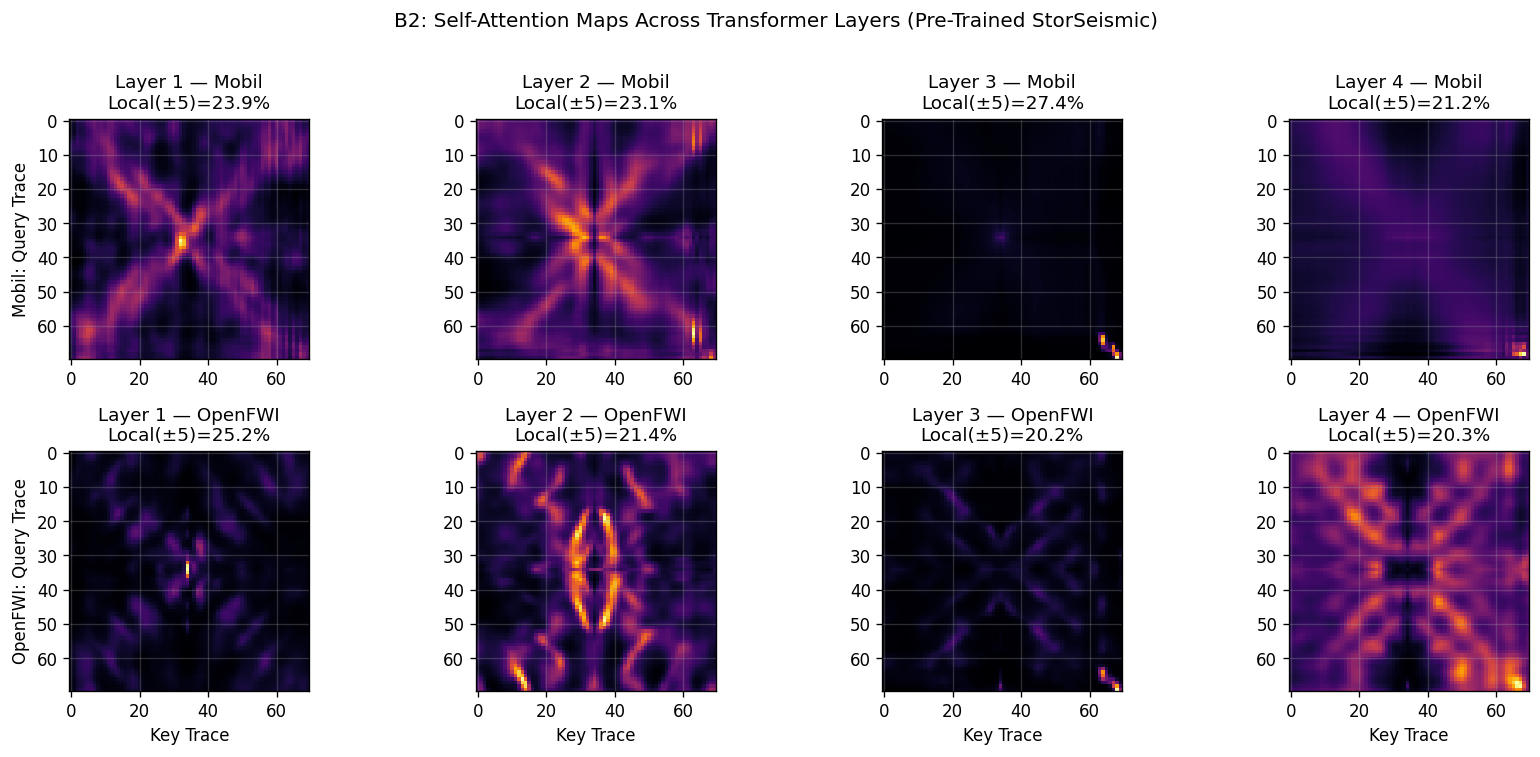

In [14]:
_, attn_mobil = nb3_pretrain.forward_with_attention(torch.tensor(f_test[10:11], device=device))
_, attn_synth = nb3_pretrain.forward_with_attention(torch.tensor(s_test[10:11], device=device))

def local_attention_ratio(attn_mat, band=5):
    n = attn_mat.shape[0]
    i, j = np.indices((n, n))
    local_mask = np.abs(i - j) <= band
    return float(attn_mat[local_mask].sum() / (attn_mat.sum() + 1e-12))

fig, axes = plt.subplots(2, NUM_LAYERS, figsize=(14, 6.2))
for l in range(NUM_LAYERS):
    am = attn_mobil[l][0]
    as_ = attn_synth[l][0]
    rm = local_attention_ratio(am, band=5)
    rs = local_attention_ratio(as_, band=5)

    im1 = axes[0, l].imshow(am, cmap="inferno", aspect="equal")
    axes[0, l].set_title(f"Layer {l+1} — Mobil\nLocal(±5)={rm*100:.1f}%")
    if l == 0:
        axes[0, l].set_ylabel("Mobil: Query Trace")

    im2 = axes[1, l].imshow(as_, cmap="inferno", aspect="equal")
    axes[1, l].set_title(f"Layer {l+1} — OpenFWI\nLocal(±5)={rs*100:.1f}%")
    axes[1, l].set_xlabel("Key Trace")
    if l == 0:
        axes[1, l].set_ylabel("OpenFWI: Query Trace")

plt.suptitle("B2: Self-Attention Maps Across Transformer Layers (Pre-Trained StorSeismic)", y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig8_b5_attention_maps.png"), bbox_inches="tight")
plt.show()

### Additional B2 Interpretability Plots: Multi-Head Dissection, Attention Rollout & Task Drift

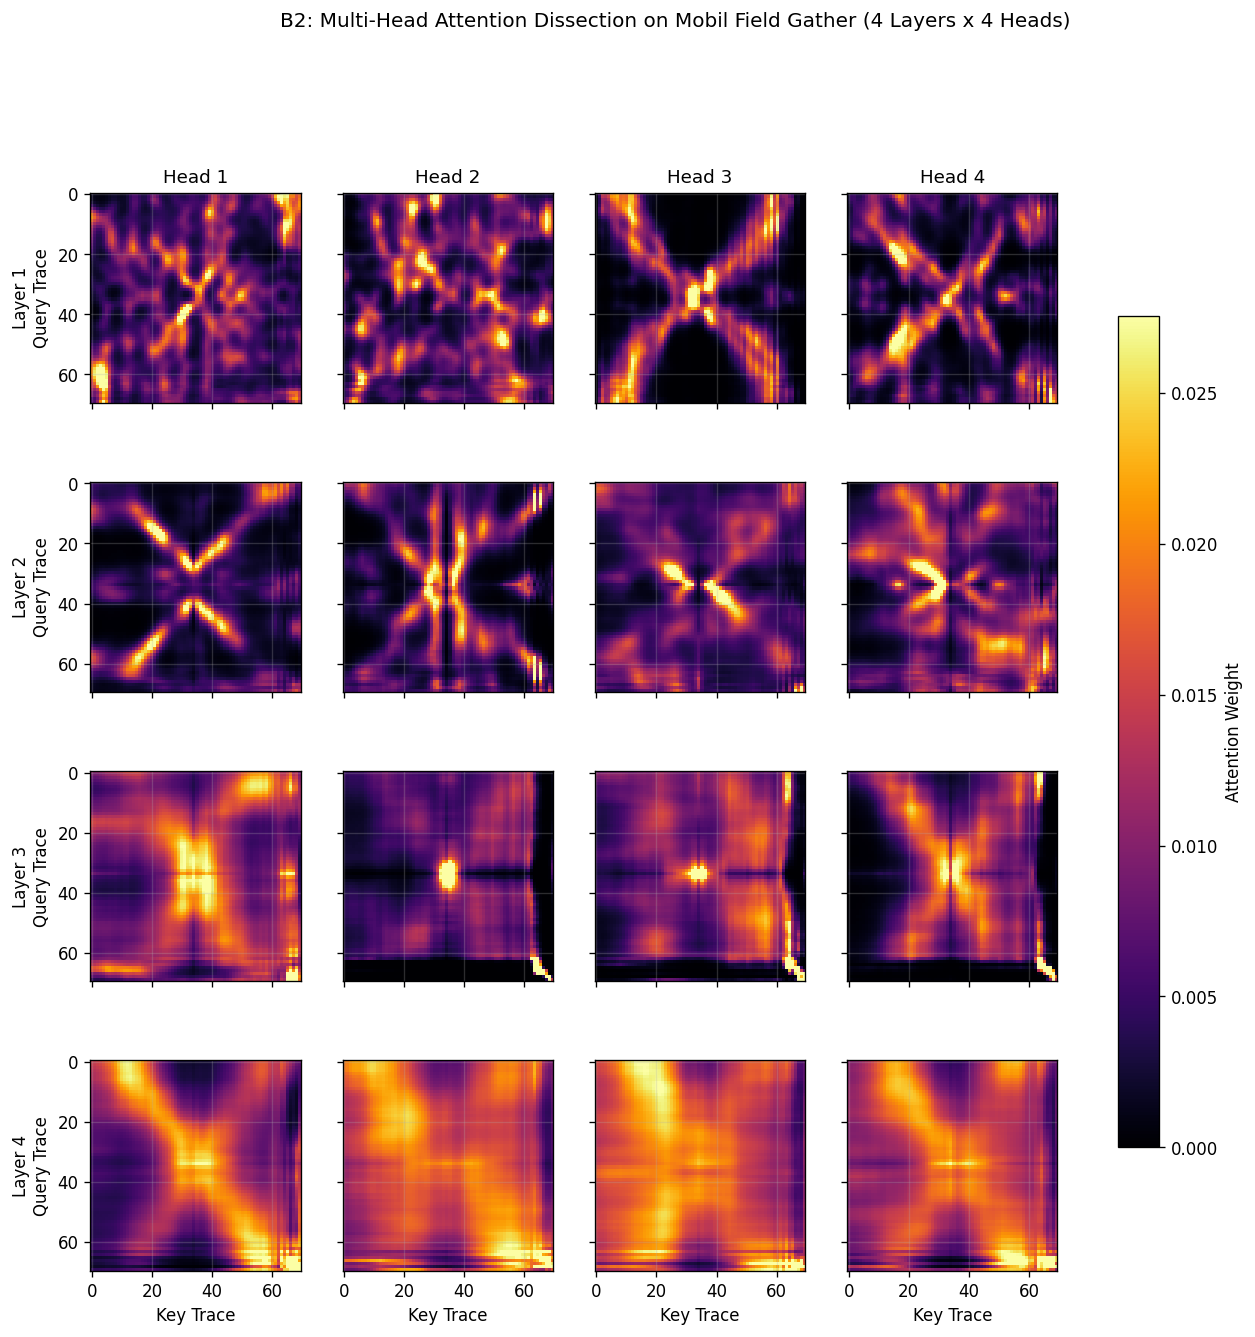

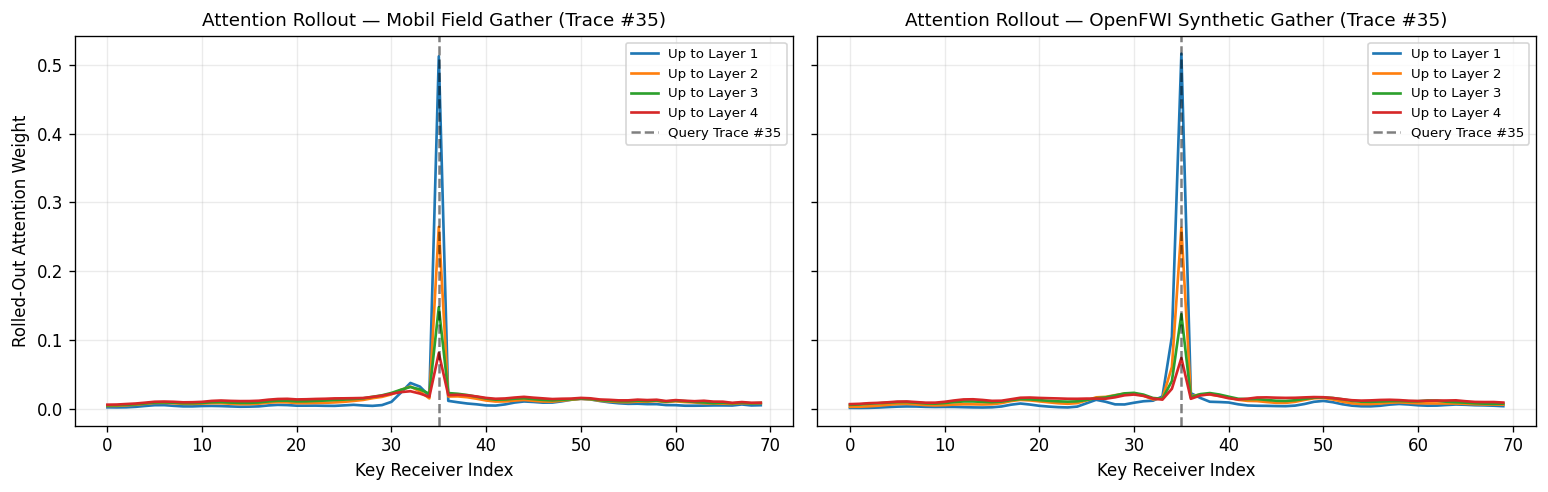

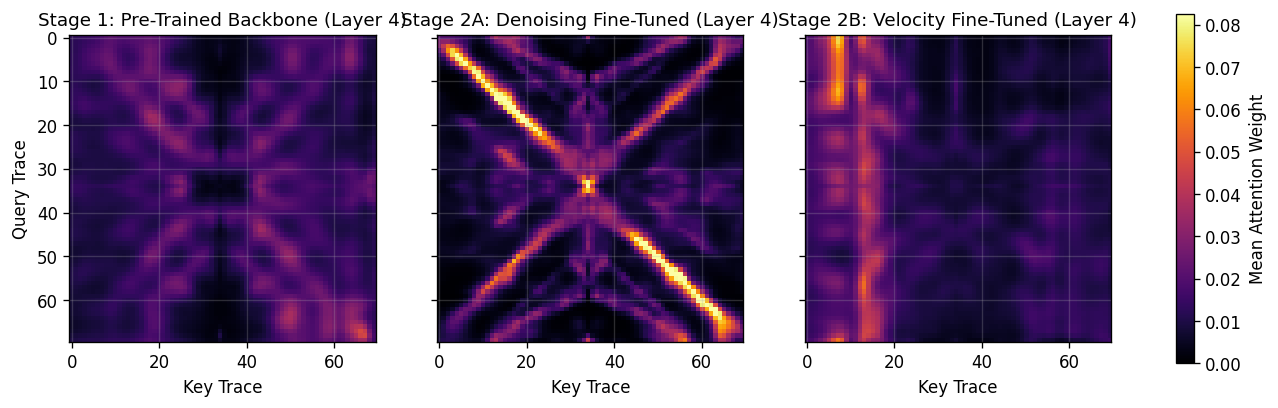

In [15]:
# --- 1. Multi-Head Attention Dissection (4x4 Grid across Layers & Heads, cf. Paper Fig 5) ---
with torch.no_grad():
    _, attn_mobil_heads = nb3_pretrain.forward_with_attention(
        torch.tensor(f_test[10:11], device=device), average_heads=False
    )
# attn_mobil_heads: list of 4 arrays, each shape (1, NUM_HEADS, 70, 70)
fig, axes = plt.subplots(NUM_LAYERS, NUM_HEADS, figsize=(13, 12), sharex=True, sharey=True)
for l_idx in range(NUM_LAYERS):
    for h_idx in range(NUM_HEADS):
        ax = axes[l_idx, h_idx]
        amap = attn_mobil_heads[l_idx][0, h_idx]
        im = ax.imshow(amap, cmap="inferno", vmin=0, vmax=np.percentile(amap, 99))
        if l_idx == 0:
            ax.set_title(f"Head {h_idx + 1}")
        if h_idx == 0:
            ax.set_ylabel(f"Layer {l_idx + 1}\nQuery Trace")
        if l_idx == NUM_LAYERS - 1:
            ax.set_xlabel("Key Trace")

fig.suptitle("B2: Multi-Head Attention Dissection on Mobil Field Gather (4 Layers x 4 Heads)", y=0.995)
fig.colorbar(im, ax=axes.ravel().tolist(), label="Attention Weight", shrink=0.75)
plt.savefig(os.path.join(FIG_DIR, "fig_b5_multihead_attention_grid.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- 2. Attention Rollout across Layers for Center Trace (#35) ---
def compute_attention_rollout(attn_list):
    """Abnar & Zuidema (2020) residual-aware attention rollout across encoder layers."""
    n = attn_list[0].shape[-1]
    rollout = np.eye(n, dtype=np.float64)
    per_layer_rollout = []
    for a in attn_list:
        a_avg = a[0]  # (70, 70)
        a_aug = 0.5 * a_avg + 0.5 * np.eye(n)
        a_aug = a_aug / a_aug.sum(axis=-1, keepdims=True)
        rollout = a_aug @ rollout
        per_layer_rollout.append(rollout.copy())
    return per_layer_rollout

with torch.no_grad():
    _, attn_mobil_avg = nb3_pretrain.forward_with_attention(torch.tensor(f_test[10:11], device=device), average_heads=True)
    _, attn_synth_avg = nb3_pretrain.forward_with_attention(torch.tensor(s_test[10:11], device=device), average_heads=True)

rollout_mobil = compute_attention_rollout(attn_mobil_avg)
rollout_synth = compute_attention_rollout(attn_synth_avg)
center_trace = 35

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
offsets = np.arange(N_TRACES)
for l_idx in range(NUM_LAYERS):
    axes[0].plot(offsets, rollout_mobil[l_idx][center_trace], label=f"Up to Layer {l_idx + 1}", lw=1.6)
    axes[1].plot(offsets, rollout_synth[l_idx][center_trace], label=f"Up to Layer {l_idx + 1}", lw=1.6)

for ax, title in zip(axes, ["Mobil Field Gather (Trace #35)", "OpenFWI Synthetic Gather (Trace #35)"]):
    ax.axvline(center_trace, color="k", linestyle="--", alpha=0.5, label="Query Trace #35")
    ax.set_title(f"Attention Rollout — {title}")
    ax.set_xlabel("Key Receiver Index")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Rolled-Out Attention Weight")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig_b5_attention_rollout.png"), dpi=300, bbox_inches="tight")
plt.show()

# --- 3. Pre-Trained vs. Fine-Tuned Layer 4 Attention Drift ---
nb3_pretrain.eval()
nb3_denoise.eval()
nb3_vel.eval()
with torch.no_grad():
    x_probe = torch.tensor(s_test[10:11], device=device)
    _, attn_pt = nb3_pretrain.forward_with_attention(x_probe, average_heads=True)
    _, attn_den = nb3_denoise.forward_with_attention(x_probe, average_heads=True)
    _, attn_vel = nb3_vel.forward_with_attention(x_probe, average_heads=True)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
drift_panels = [
    (attn_pt[-1][0], "Stage 1: Pre-Trained Backbone (Layer 4)"),
    (attn_den[-1][0], "Stage 2A: Denoising Fine-Tuned (Layer 4)"),
    (attn_vel[-1][0], "Stage 2B: Velocity Fine-Tuned (Layer 4)"),
]
vmax_d = max(np.percentile(p[0], 99) for p in drift_panels)
for ax, (amap, title) in zip(axes, drift_panels):
    im = ax.imshow(amap, cmap="inferno", vmin=0, vmax=vmax_d)
    ax.set_title(title)
    ax.set_xlabel("Key Trace")
axes[0].set_ylabel("Query Trace")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Mean Attention Weight", shrink=0.9)
plt.savefig(os.path.join(FIG_DIR, "fig_b5_attention_drift_layer4.png"), dpi=300, bbox_inches="tight")
plt.show()

## 10. Master Summary Table & Exported Figures


In [16]:
print("=" * 78)
print("STORSEISMIC EXTENDED EXPERIMENTS — MASTER SUMMARY")
print("=" * 78)
print(f"[Baseline nb3] OpenFWI Denoise SNR : {synth_den_diag['output_snr_db']:.2f} dB (r={synth_den_diag['corr_r']:.4f})")
print(f"[Baseline nb3] Mobil Field Corr    : {mobil_diag['mobil_corr_r']:.4f} | Removed Energy: {mobil_diag['mobil_removed_energy_pct']:.2f}%")
print(f"[Baseline nb3] OpenFWI Vel MAE     : {synth_vel_diag['vel_mae_ms']:.1f} m/s (R^2={synth_vel_diag['vel_r2']:.4f})")
print("-" * 78)
print("[Exp A1] Sample Efficiency (10% -> 100% labels):")
for f, dp, ds, vp, vs in zip(
    a1_results["fractions"], a1_results["pretrained"]["den_snr"], a1_results["scratch"]["den_snr"],
    a1_results["pretrained"]["vel_mae"], a1_results["scratch"]["vel_mae"]
):
    print(f"   {int(f*100):3d}% | Denoise SNR: PT={dp:5.2f} vs SC={ds:5.2f} dB | Vel MAE: PT={vp:5.1f} vs SC={vs:5.1f} m/s")
print("-" * 78)
print("[Exp A2] Partial Layer Freezing Sweep:")
for nf, ds, vm, mc in zip(a2_results["freeze_levels"], a2_results["den_snr"], a2_results["vel_mae"], a2_results["mobil_corr"]):
    print(f"   Freeze={nf} | OpenFWI SNR={ds:5.2f} dB | Vel MAE={vm:5.1f} m/s | Mobil Corr={mc:.4f}")
print("-" * 78)
print("[Exp A3] Pre-Training Data Mix:")
for reg, ds, vm, mc in zip(a3_results["regimes"], a3_results["den_snr"], a3_results["vel_mae"], a3_results["mobil_corr"]):
    print(f"   {reg:18s} | OpenFWI SNR={ds:5.2f} dB | Vel MAE={vm:5.1f} m/s | Mobil Corr={mc:.4f}")
print("-" * 78)
print("[Exp A4] Model Scaling:")
for nm, p, ds, vm, lat in zip(a5_results["models"], a5_results["params"], a5_results["den_snr"], a5_results["vel_mae"], a5_results["latency_ms"]):
    print(f"   {nm:10s} ({p/1e6:4.2f}M) | SNR={ds:5.2f} dB | Vel MAE={vm:5.1f} m/s | Latency={lat:.2f} ms")
print("-" * 78)
print("[Exp B1] Zero-Shot Mobil Dead-Trace Interpolation (Masked-Trace SNR dB):")
print(f"   Random 20% : Linear={b2_results['random20']['linear']:.2f} | Cubic={b2_results['random20']['cubic']:.2f} | StorSeismic={b2_results['random20']['storseismic']:.2f} dB")
print(f"   5-Trace Gap: Linear={b2_results['gap5']['linear']:.2f} | Cubic={b2_results['gap5']['cubic']:.2f} | StorSeismic={b2_results['gap5']['storseismic']:.2f} dB")
print("=" * 78)
print("Saved high-DPI report figures:")
for fn in sorted(os.listdir(FIG_DIR)):
    print("  -", os.path.join(FIG_DIR, fn))

STORSEISMIC EXTENDED EXPERIMENTS — MASTER SUMMARY
[Baseline nb3] OpenFWI Denoise SNR : 16.18 dB (r=0.9849)
[Baseline nb3] Mobil Field Corr    : -0.0008 | Removed Energy: 100.82%
[Baseline nb3] OpenFWI Vel MAE     : 307.0 m/s (R^2=0.6917)
------------------------------------------------------------------------------
[Exp A1] Sample Efficiency (10% -> 100% labels):
    10% | Denoise SNR: PT= 9.17 vs SC=-0.83 dB | Vel MAE: PT=315.1 vs SC=388.2 m/s
    25% | Denoise SNR: PT=12.13 vs SC= 3.47 dB | Vel MAE: PT=352.9 vs SC=398.0 m/s
    50% | Denoise SNR: PT=13.27 vs SC= 6.11 dB | Vel MAE: PT=309.9 vs SC=376.3 m/s
   100% | Denoise SNR: PT=16.18 vs SC= 9.39 dB | Vel MAE: PT=307.0 vs SC=367.0 m/s
------------------------------------------------------------------------------
[Exp A2] Partial Layer Freezing Sweep:
   Freeze=0 | OpenFWI SNR=15.05 dB | Vel MAE=283.3 m/s | Mobil Corr=0.0007
   Freeze=1 | OpenFWI SNR=15.03 dB | Vel MAE=313.0 m/s | Mobil Corr=-0.0000
   Freeze=2 | OpenFWI SNR=16.18 d